# Heads-Up Limit Texas Hold'em: Strategy & Game Theory Engine

## Context

Poker is a game of **imperfect information**: you never see your opponent's cards, so every decision is made under uncertainty. That makes it a classic testbed for game theory. Heads-up (one-on-one) **Fixed-Limit** Hold'em is the smallest version of the game that is still strategically rich. Every bet has a fixed size, so a decision comes down to *fold, call or raise*, and the whole game can be simulated quickly enough to run tens of thousands of hands.

**Research question:** *How do different kinds of decision-makers perform against each other?* We place every strategy on two game-theoretic axes:

| Axis | Low end | High end |
|---|---|---|
| **Rationality** | Bounded / irrational heuristics (rules of thumb, ignoring information) | Rational: maximise expected value using probabilities |
| **Equilibrium** | Static / unbalanced: the same rules every hand, regardless of the opponent | Dynamic / exploitative: learns the opponent's tendencies and adjusts |

## Goals and division of labor

| Goal | What it delivers | Owner | Section |
|---|---|---|---|
| **Basic (40%)** | OOP engine (`Card`, `Deck`, `HandEvaluator`, `Player`, `GameEngine`), 7-to-5 card evaluator with tie-breakers, showdown & pot logic, autonomous AI-vs-AI loop, the base Expected Value formula | Augustine | 1 |
| **Intermediate (20%)** | Monte Carlo equity simulator (Kazzie); error convergence vs. the theoretical $1/\sqrt{N}$ rate, 13×13 pre-flop equity heatmap, post-flop equity breakdown (Marc) | Kazzie & Marc | 2 |
| **Advanced (20%)** | Heuristic agents: Calling Station, Rock, Maniac (Jada); EV agent, Adaptive exploitative agent, 10,000-hand round-robin tournament with bb/100 (Poleen) | Jada & Poleen | 3 |
| **Visualizations & readability (20%)** | Charts in every section; PEP8-compliant code | Everyone | All |

## How to read this notebook

Every subsection follows the same pattern: **what & why → code → tests / sanity checks → chart → what it shows**. Run the cells top to bottom (*Run All*); every test is an `assert`, so a cell that finishes without an error has passed.

- **Section 1** builds and verifies the game itself.
- **Section 2** builds the probability engine and shows that its error behaves exactly as theory predicts.
- **Section 3** builds the agents, verifies that each behaves as its label claims, and runs the tournament.
- **Section 4** discusses the results and their limits.
- **Appendix A** lets you play against a bot yourself. A guide to the less common Python tools used is in the separate file `Python_Concepts_Guide.md`.

**Extensions beyond the proposal:** the engine also supports **No-Limit** betting (`betting="no-limit"`, its default, used in Section 1 and Appendix A) and a clickable 1 human vs. AI table. All agent experiments in Section 3 use **Fixed-Limit**, the format of the study.

---
# 1. Basic Goal: The Game Engine
*Owner: Augustine*

A correct game is the foundation for everything else: if the evaluator ranks a hand wrongly or the engine leaks chips, every later result is meaningless. This section builds the engine with object-oriented classes and then **tests each piece in isolation** (cards, hand ranking, betting rules, chip conservation) before letting AI players loose on it.

In [210]:
# 1.1 Imports & global configuration
import html
import math
import os
import pickle
import random
import time
from abc import ABC, abstractmethod
from collections import Counter
from dataclasses import dataclass
from enum import IntEnum
from functools import total_ordering
from itertools import combinations

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

RANKS = "23456789TJQKA"
RANK_VALUES = {char: value for value, char in enumerate(RANKS, start=2)}
RANK_NAMES = {
    2: "Two",
    3: "Three",
    4: "Four",
    5: "Five",
    6: "Six",
    7: "Seven",
    8: "Eight",
    9: "Nine",
    10: "Ten",
    11: "Jack",
    12: "Queen",
    13: "King",
    14: "Ace",
}
RANK_PLURALS = {value: name + "s" for value, name in RANK_NAMES.items()}
RANK_PLURALS[6] = "Sixes"

SUITS = "cdhs"  # clubs < diamonds < hearts < spades (used only to sort)
SUIT_SYMBOLS = {"c": "♣", "d": "♦", "h": "♥", "s": "♠"}

STREETS = ("Pre-Flop", "Flop", "Turn", "River")
BOARD_CARDS_PER_STREET = {"Pre-Flop": 0, "Flop": 3, "Turn": 1, "River": 1}

# One chart palette for every figure in the notebook.
INK, MUTED, GRID = "#191919", "#666666", "#e7e7e7"
SERIES = [
    "#257de0",  # blue
    "#f47230",  # orange
    "#00b894",  # aqua
    "#f2a600",  # yellow
    "#ee7fac",  # magenta
    "#008a17",  # green
    "#6a4ce2",  # violet
    "#ec4647",  # red
]
WIN_COLOR, TIE_COLOR, LOSS_COLOR = "#257de0", "#b3b3b3", "#ec4647"

## 1.1–1.2 Cards and the deck
A `Card` is an immutable value (rank 2–14, suit). Making it immutable and hashable lets cards live in sets, which is how duplicate cards are caught everywhere in the project. The `Deck` owns its own random generator so a seed reproduces a whole session exactly.

In [211]:
# 1.2 Card & Deck classes
@dataclass(frozen=True, order=True)
class Card:
    """An immutable playing card. Cards sort by rank first, then by suit."""

    rank: int  # 2..14 (14 = Ace)
    suit: str  # one of 'c', 'd', 'h', 's'

    def __post_init__(self):
        if self.rank not in RANK_NAMES:
            raise ValueError(f"Invalid rank: {self.rank}")
        if self.suit not in SUITS:
            raise ValueError(f"Invalid suit: {self.suit}")

    @classmethod
    def from_str(cls, text):
        """Build a card from short notation, e.g. 'Ah', 'Td', '7c'."""
        return cls(RANK_VALUES[text[0].upper()], text[1].lower())

    @property
    def rank_char(self):
        return RANKS[self.rank - 2]

    def __str__(self):
        return f"{self.rank_char}{SUIT_SYMBOLS[self.suit]}"

    def __repr__(self):
        return f"Card('{self.rank_char}{self.suit}')"


def parse_cards(text):
    """Parse a space-separated card string: parse_cards('Ah Kd 7c')."""
    return [Card.from_str(token) for token in text.split()]


def format_cards(cards):
    return " ".join(str(card) for card in cards)


class Deck:
    """A standard 52-card deck with its own random generator (seedable)."""

    def __init__(self, rng=None):
        self.rng = rng or random.Random()
        self.cards = []
        self.reset()

    def reset(self):
        self.cards = [Card(rank, suit) for suit in SUITS for rank in RANK_NAMES]

    def shuffle(self):
        self.rng.shuffle(self.cards)

    def deal(self, count=1):
        if count > len(self.cards):
            raise ValueError("Not enough cards left in the deck.")
        return [self.cards.pop() for _ in range(count)]

    def burn(self):
        self.deal(1)

    def __len__(self):
        return len(self.cards)


deck = Deck(random.Random(42))
deck.shuffle()
print("Sorted sample:", format_cards(sorted(deck.deal(5), reverse=True)))
print("Cards left:", len(deck))

Sorted sample: T♠ 9♣ 6♦ 3♠ 3♣
Cards left: 47


## 1.3 Hand evaluator
`HandEvaluator.best_hand` scores all **21** five-card combinations of a 7-card hand and keeps the best. A `HandRank` compares on `(category, tiebreak)`: the category (pair, flush, ...) first, then the ranks that matter in order (e.g. two pair K-K-7-7-A → `(13, 7, 14)`), which resolves kickers. Special cases: the **wheel** (A-2-3-4-5) is the lowest straight, and a royal flush is its own category.

In [212]:
# 1.3 Hand evaluator (best 5 of up to 7 cards)
class HandCategory(IntEnum):
    HIGH_CARD = 0
    ONE_PAIR = 1
    TWO_PAIR = 2
    THREE_OF_A_KIND = 3
    STRAIGHT = 4
    FLUSH = 5
    FULL_HOUSE = 6
    FOUR_OF_A_KIND = 7
    STRAIGHT_FLUSH = 8
    ROYAL_FLUSH = 9

    @property
    def label(self):
        return self.name.replace("_", " ").title().replace(" Of A ", " of a ")


@total_ordering
@dataclass(frozen=True, eq=False)
class HandRank:
    """The value of a 5-card hand.

    Hands compare on (category, tiebreak). `tiebreak` lists the ranks that
    matter in order of importance, e.g. Two Pair K-K-7-7-A -> (13, 7, 14).
    """

    category: HandCategory
    tiebreak: tuple
    cards: tuple  # the five cards, ordered for display

    @property
    def key(self):
        return (self.category, self.tiebreak)

    def __eq__(self, other):
        return self.key == other.key

    def __lt__(self, other):
        return self.key < other.key

    @property
    def strength(self):
        """A continuous score in [0, 10): category + kicker fraction.

        Every tiebreak rank is < 15, so the base-15 fraction preserves the
        exact lexicographic ordering of the hands.
        """
        fraction = sum(rank / 15 ** (i + 1) for i, rank in enumerate(self.tiebreak))
        return self.category + fraction

    def describe(self):
        cat, t = self.category, self.tiebreak
        name, plural = RANK_NAMES, RANK_PLURALS
        kickers = lambda ranks: " ".join(RANKS[r - 2] for r in ranks)
        if cat == HandCategory.ROYAL_FLUSH:
            return "Royal Flush"
        if cat == HandCategory.STRAIGHT_FLUSH:
            return f"Straight Flush, {name[t[0]]} high"
        if cat == HandCategory.FOUR_OF_A_KIND:
            return f"Four {plural[t[0]]}, kicker {kickers(t[1:])}"
        if cat == HandCategory.FULL_HOUSE:
            return f"Full House, {plural[t[0]]} full of {plural[t[1]]}"
        if cat == HandCategory.FLUSH:
            return f"Flush, {kickers(t)}"
        if cat == HandCategory.STRAIGHT:
            return f"Straight, {name[t[0]]} high"
        if cat == HandCategory.THREE_OF_A_KIND:
            return f"Three {plural[t[0]]}, kickers {kickers(t[1:])}"
        if cat == HandCategory.TWO_PAIR:
            return f"Two Pair, {plural[t[0]]} & {plural[t[1]]}, kicker {kickers(t[2:])}"
        if cat == HandCategory.ONE_PAIR:
            return f"Pair of {plural[t[0]]}, kickers {kickers(t[1:])}"
        return f"High Card, {kickers(t)}"

    def __repr__(self):
        return f"<{self.describe()} | {format_cards(self.cards)}>"


class HandEvaluator:
    """Stateless poker hand evaluation utilities."""

    @staticmethod
    def evaluate_five(five):
        if len(five) != 5:
            raise ValueError("evaluate_five needs exactly 5 cards.")
        ranks = sorted((card.rank for card in five), reverse=True)
        counts = Counter(ranks)
        # Group ranks by (multiplicity, rank): quads before trips before pairs.
        groups = sorted(
            counts.items(), key=lambda item: (item[1], item[0]), reverse=True
        )
        grouped_ranks = tuple(rank for rank, _ in groups)
        shape = [count for _, count in groups]

        is_flush = len({card.suit for card in five}) == 1
        straight_high = None
        if len(counts) == 5:
            if ranks[0] - ranks[4] == 4:
                straight_high = ranks[0]
            elif ranks == [14, 5, 4, 3, 2]:  # the wheel: A-2-3-4-5
                straight_high = 5

        # Display order: biggest group first; in a wheel the Ace goes last.
        def display_key(card):
            rank = 1 if straight_high == 5 and card.rank == 14 else card.rank
            return (counts[card.rank], rank, card.suit)

        ordered = tuple(sorted(five, key=display_key, reverse=True))

        if straight_high and is_flush:
            category = (
                HandCategory.ROYAL_FLUSH
                if straight_high == 14
                else HandCategory.STRAIGHT_FLUSH
            )
            return HandRank(category, (straight_high,), ordered)
        if shape == [4, 1]:
            return HandRank(HandCategory.FOUR_OF_A_KIND, grouped_ranks, ordered)
        if shape == [3, 2]:
            return HandRank(HandCategory.FULL_HOUSE, grouped_ranks, ordered)
        if is_flush:
            return HandRank(HandCategory.FLUSH, tuple(ranks), ordered)
        if straight_high:
            return HandRank(HandCategory.STRAIGHT, (straight_high,), ordered)
        if shape == [3, 1, 1]:
            return HandRank(HandCategory.THREE_OF_A_KIND, grouped_ranks, ordered)
        if shape == [2, 2, 1]:
            return HandRank(HandCategory.TWO_PAIR, grouped_ranks, ordered)
        if shape == [2, 1, 1, 1]:
            return HandRank(HandCategory.ONE_PAIR, grouped_ranks, ordered)
        return HandRank(HandCategory.HIGH_CARD, tuple(ranks), ordered)

    @classmethod
    def best_hand(cls, hole_cards, board):
        """Best 5-card HandRank from 2 hole cards + 3..5 board cards."""
        cards = list(hole_cards) + list(board)
        if not 5 <= len(cards) <= 7:
            raise ValueError(f"Need 5-7 cards to evaluate, got {len(cards)}.")
        if len(set(cards)) != len(cards):
            raise ValueError("Duplicate cards detected.")
        return max(cls.evaluate_five(combo) for combo in combinations(cards, 5))

    @classmethod
    def showdown(cls, hands, board):
        """Evaluate {name: hole_cards}; return (winner_names, {name: HandRank})."""
        results = {name: cls.best_hand(hole, board) for name, hole in hands.items()}
        best = max(results.values())
        winners = [name for name, rank in results.items() if rank == best]
        return winners, results

### 1.4 Evaluator tests
One hand per category, the full category ladder, the wheel, best-5-of-7 upgrades, kicker battles, split pots and flush-vs-flush comparisons.

In [213]:
# 1.4 Evaluator unit tests
def check(hole, board, expected_category):
    rank = HandEvaluator.best_hand(parse_cards(hole), parse_cards(board))
    assert rank.category == expected_category, (hole, board, rank)
    return rank


royal = check("Ah Kh", "Qh Jh Th 2c 3d", HandCategory.ROYAL_FLUSH)
steel_wheel = check("Ac 2c", "3c 4c 5c Kd Kh", HandCategory.STRAIGHT_FLUSH)
quads = check("9s 9d", "9h 9c Ks 2d 3h", HandCategory.FOUR_OF_A_KIND)
boat = check("Ks Kd", "Kh 7c 7d 2s 3h", HandCategory.FULL_HOUSE)
flush = check("Ad 3d", "Kd 8d 2d Qs Js", HandCategory.FLUSH)
wheel = check("As 2d", "3c 4h 5s Kd Qh", HandCategory.STRAIGHT)
six_high = check("6s 2d", "3c 4h 5s Kd Qh", HandCategory.STRAIGHT)
trips = check("7s 7d", "7h Ac Ks 2d 4h", HandCategory.THREE_OF_A_KIND)
two_pair = check("Ks 7d", "Kh 7c Ad 2s 3h", HandCategory.TWO_PAIR)
pair = check("Qs Qd", "Ah 9c 5d 3s 2h", HandCategory.ONE_PAIR)
high = check("As Jd", "9h 7c 5d 3s 2h", HandCategory.HIGH_CARD)

# Category ordering and special cases.
ladder = [high, pair, two_pair, trips, six_high, flush, boat, quads, steel_wheel, royal]
assert all(a < b for a, b in zip(ladder, ladder[1:]))
assert wheel < six_high, "The wheel (A-5) is the lowest straight."
assert wheel.cards[-1].rank == 14, "The Ace is displayed last in a wheel."

# Best 5 of 7: a 6th straight card upgrades a straight.
assert check("6d 7d", "2s 3h 4c 5s Kd", HandCategory.STRAIGHT).tiebreak == (7,)

# Kicker resolution: same pair, better kicker wins.
board = "Kh 8c 5d 3s 2h"
winners, _ = HandEvaluator.showdown(
    {"A": parse_cards("Ks Qd"), "B": parse_cards("Kd Jc")}, parse_cards(board)
)
assert winners == ["A"], "Queen kicker beats Jack kicker."

# Two pair: the 5th card kicker decides.
winners, _ = HandEvaluator.showdown(
    {"A": parse_cards("As 4d"), "B": parse_cards("Qd 4c")},
    parse_cards("Kh Kc 9d 9s 2h"),
)
assert winners == ["A"]

# Board plays for both players -> split pot.
winners, _ = HandEvaluator.showdown(
    {"A": parse_cards("2c 3d"), "B": parse_cards("2d 3c")},
    parse_cards("As Ks Qs Js Ts"),
)
assert winners == ["A", "B"]

# Full houses compare trips first, then the pair.
assert check("Ks Kd", "Kh 2c 2d 9s 8h", HandCategory.FULL_HOUSE) > check(
    "Qs Qd", "Qh Ac Ad 9s 8h", HandCategory.FULL_HOUSE
)

# Flush vs flush is decided card by card.
assert check("Ad 2d", "Kd 8d 4d Qs Js", HandCategory.FLUSH) > check(
    "Ad 3d", "Qd 8d 4d Qs Js", HandCategory.FLUSH
)

for rank in reversed(ladder):
    print(f"{rank.category.label:<16} {format_cards(rank.cards):<16} {rank.describe()}")
print("\nAll evaluator tests passed.")

Royal Flush      A♥ K♥ Q♥ J♥ T♥   Royal Flush
Straight Flush   5♣ 4♣ 3♣ 2♣ A♣   Straight Flush, Five high
Four of a Kind   9♠ 9♥ 9♦ 9♣ K♠   Four Nines, kicker K
Full House       K♠ K♥ K♦ 7♦ 7♣   Full House, Kings full of Sevens
Flush            A♦ K♦ 8♦ 3♦ 2♦   Flush, A K 8 3 2
Straight         6♠ 5♠ 4♥ 3♣ 2♦   Straight, Six high
Three of a Kind  7♠ 7♥ 7♦ A♣ K♠   Three Sevens, kickers A K
Two Pair         K♠ K♥ 7♦ 7♣ A♦   Two Pair, Kings & Sevens, kicker A
One Pair         Q♠ Q♦ A♥ 9♣ 5♦   Pair of Queens, kickers A 9 5
High Card        A♠ J♦ 9♥ 7♣ 5♦   High Card, A J 9 7 5

All evaluator tests passed.


## 1.5 Players, table state and simple agents
An agent only ever sees a frozen `TableState`, which holds its own cards, the board, the pot and its legal actions. It can't see the opponent's cards and can't modify the game, so every agent in Section 3 competes on equal information.

In [214]:
# 1.5 Player, table state & simple agents
@dataclass(frozen=True)
class TableState:
    """A snapshot of everything an agent is allowed to see when acting.

    Bet and raise sizes are "raise to" amounts: the player's total bet on
    this street after the action, as in standard hold'em.
    """

    street: str
    betting: str  # "no-limit" or "limit"
    board: tuple
    hole_cards: tuple
    pot: int
    to_call: int
    current_bet: int  # the highest bet on this street so far
    street_bet: int  # what this player already put in on this street
    min_raise_to: int  # smallest legal bet/raise
    max_raise_to: int  # largest legal bet/raise (all-in in no-limit)
    bets_this_street: int
    chips: int
    opponent_chips: int
    legal_actions: tuple
    action_history: tuple

    def raise_to_for_pot_fraction(self, fraction):
        """Raise-to amount for a bet worth `fraction` of the pot (counting
        the call), clamped to the legal range. 1.0 = a pot-sized raise."""
        target = self.current_bet + round(fraction * (self.pot + self.to_call))
        return max(self.min_raise_to, min(self.max_raise_to, target))


class Player:
    """A seat at the table: chip stack, hole cards and bets this hand."""

    def __init__(self, name, chips, agent):
        self.name = name
        self.chips = chips
        self.agent = agent
        self.reset_for_hand()

    def reset_for_hand(self):
        self.hole_cards = []
        self.street_bet = 0  # chips put in on the current street
        self.total_bet = 0  # chips put in during the whole hand
        self.folded = False

    def commit(self, amount):
        """Move chips from the stack into the pot (capped at the stack)."""
        amount = min(amount, self.chips)
        self.chips -= amount
        self.street_bet += amount
        self.total_bet += amount
        return amount

    @property
    def is_all_in(self):
        return self.chips == 0 and not self.folded

    def __repr__(self):
        return f"Player({self.name!r}, chips={self.chips}, agent={self.agent.name})"


class Agent:
    """Base class: an agent maps a TableState to one of its legal actions.

    `decide` returns "fold", "check", "call", "all-in", or a sized bet as
    ("bet", raise_to) / ("raise", raise_to). A bare "bet" or "raise" means
    the minimum legal size.
    """

    name = "Agent"
    interactive = False  # True for seats controlled by a person

    def decide(self, state):
        raise NotImplementedError


class PassiveAgent(Agent):
    """Always checks or calls: guarantees the hand reaches showdown."""

    name = "Passive"

    def decide(self, state):
        return "check" if "check" in state.legal_actions else "call"


class ScriptedAgent(Agent):
    """Plays a fixed list of actions and remembers every state it saw (tests)."""

    name = "Scripted"

    def __init__(self, actions):
        self.actions = list(actions)
        self.seen = []

    def decide(self, state):
        self.seen.append(state)
        return self.actions.pop(0)


class RandomAgent(Agent):
    """Dummy agent: picks a legal action at random (weighted) and, in
    no-limit, a random size from min-raise, 1/2, 3/4 or a full pot."""

    name = "Random"
    DEFAULT_WEIGHTS = {
        "fold": 1,
        "check": 4,
        "call": 4,
        "bet": 2,
        "raise": 2,
        "all-in": 0.2,
    }
    POT_FRACTIONS = (0.5, 0.75, 1.0)

    def __init__(self, weights=None, rng=None):
        self.weights = weights or self.DEFAULT_WEIGHTS
        self.rng = rng or random.Random()

    def decide(self, state):
        actions = list(state.legal_actions)
        weights = [self.weights.get(action, 1) for action in actions]
        action = self.rng.choices(actions, weights=weights, k=1)[0]
        if action in ("bet", "raise") and state.betting == "no-limit":
            sizes = [state.min_raise_to] + [
                state.raise_to_for_pot_fraction(f) for f in self.POT_FRACTIONS
            ]
            return action, self.rng.choice(sizes)
        return action


class HumanAgent(Agent):
    """Interactive seat. The table UI (Appendix A) supplies its actions with
    buttons; `decide` is a plain-text input() fallback for play_hand().
    Text commands: f, x, c, a (all-in), or "b 20" / "r 20" to bet/raise to 20.
    """

    name = "Human"
    interactive = True
    SHORTCUTS = {
        "f": "fold",
        "x": "check",
        "c": "call",
        "b": "bet",
        "r": "raise",
        "a": "all-in",
    }

    def decide(self, state):
        print(f"\n--- {state.street} | Board: {format_cards(state.board) or '-'}")
        print(
            f"Your cards: {format_cards(state.hole_cards)} | Chips: {state.chips}"
            f" | Pot: {state.pot} | To call: {state.to_call}"
            f" | Bet/raise to: {state.min_raise_to}-{state.max_raise_to}"
        )
        options = "/".join(state.legal_actions)
        while True:
            tokens = input(f"Action ({options}): ").strip().lower().split()
            if not tokens:
                continue
            choice = self.SHORTCUTS.get(tokens[0], tokens[0])
            if choice not in state.legal_actions:
                print(f"'{choice}' is not legal here. Choose from: {options}")
            elif choice in ("bet", "raise") and len(tokens) > 1:
                amount = int(tokens[1])
                if state.min_raise_to <= amount <= state.max_raise_to:
                    return choice, amount
                print(f"Size must be {state.min_raise_to}-{state.max_raise_to}.")
            else:
                return choice

## 1.6 The game engine
`GameEngine` runs heads-up hands: blinds, dealing, four betting rounds, fold or showdown, and pot settlement (including returning an uncalled bet and splitting a tied pot). Heads-up rules apply: the button posts the small blind and acts first pre-flop, last afterwards. In **Fixed-Limit** a bet is one *small bet* (= big blind) pre-flop and on the flop, one *big bet* (= 2 big blinds) on the turn and river, with at most 4 bets per street.

In [215]:
# 1.6 Stateful heads-up GameEngine (No-Limit or Fixed-Limit)
class GameEngine:
    """Runs heads-up Texas Hold'em hands between two players.

    Heads-up rules: the button posts the small blind and acts first
    pre-flop; the big blind acts first on the flop, turn and river.

    betting="no-limit" (default): players choose their size. The minimum
    bet is the big blind, a raise must be at least as big as the previous
    bet or raise on that street, there is no cap on raises, and a player
    may go all-in at any time. An all-in for less than a full raise is
    allowed. Any part of a bet the opponent can't match is returned.

    betting="limit": fixed sizes - the small bet (= big blind) pre-flop and
    on the flop, the big bet (= 2x big blind) on the turn and river, capped
    at `bet_cap` bets per street (a bet plus three raises).

    `hand_steps()` is a generator that pauses at every decision, which lets
    a button-driven UI feed in a human's actions. `play_hand()` drives the
    same generator by asking each seat's agent.

    When a human sits at the table, the bot's hole cards are kept out of
    every log; they are only shown if the hand reaches showdown.
    """

    BETTING_STRUCTURES = ("no-limit", "limit")

    def __init__(
        self,
        player_one,
        player_two,
        small_blind=1,
        big_blind=2,
        betting="no-limit",
        bet_cap=4,
        seed=None,
        verbose=True,
    ):
        if betting not in self.BETTING_STRUCTURES:
            raise ValueError(f"betting must be one of {self.BETTING_STRUCTURES}")
        self.betting = betting
        self.players = [player_one, player_two]
        self.small_blind = small_blind
        self.big_blind = big_blind
        self.small_bet = big_blind
        self.big_bet = 2 * big_blind
        self.bet_cap = bet_cap
        self.rng = random.Random(seed)
        self.deck = Deck(self.rng)
        self.verbose = verbose
        self.button = 0  # index of the player on the button
        self.hand_number = 0
        self.street = None
        self.board = []
        self.action_log = []
        self.hand_log = []  # (owner, message) lines for the current hand
        self.history = []  # one record (dict) per completed hand
        # With no human seated, it is a spectator simulation: show everything.
        self.reveal_all = not any(p.agent.interactive for p in self.players)

    # ----- helpers ---------------------------------------------------------
    def can_see(self, owner):
        """Whether a log line that is private to `owner` may be shown."""
        if owner is None or self.reveal_all:
            return True
        return any(p.name == owner and p.agent.interactive for p in self.players)

    def log(self, message, owner=None):
        """Record a log line; `owner` marks it private to that player."""
        self.hand_log.append((owner, message))
        if self.verbose and self.can_see(owner):
            print(message)

    @property
    def pot(self):
        return sum(player.total_bet for player in self.players)

    def total_chips(self):
        return sum(player.chips for player in self.players) + self.pot

    def _live_players(self):
        return [player for player in self.players if not player.folded]

    def _bet_size(self, street):
        return self.small_bet if street in ("Pre-Flop", "Flop") else self.big_bet

    # ----- hand flow -------------------------------------------------------
    def play_hand(self):
        """Play one full hand, asking each seat's agent for its decisions."""
        steps = self.hand_steps()
        action = None
        while True:
            try:
                player, state = steps.send(action)
            except StopIteration as finished:
                return finished.value  # the hand record
            action = player.agent.decide(state)

    def hand_steps(self):
        """Generator version of a hand.

        Yields (player, TableState) whenever someone must act; resume it with
        .send(action). When the hand is over it returns the hand record.
        """
        if any(player.chips == 0 for player in self.players):
            raise RuntimeError("A player is out of chips; the session is over.")
        self.hand_number += 1
        stacks_before = {player.name: player.chips for player in self.players}
        self.board, self.action_log, self.hand_log = [], [], []
        for player in self.players:
            player.reset_for_hand()
        self.deck.reset()
        self.deck.shuffle()

        sb_player = self.players[self.button]
        bb_player = self.players[1 - self.button]
        self.log(f"\n===== Hand #{self.hand_number} | Button: {sb_player.name} =====")
        sb_player.commit(self.small_blind)
        bb_player.commit(self.big_blind)
        self.log(
            f"{sb_player.name} posts SB {self.small_blind}, "
            f"{bb_player.name} posts BB {self.big_blind}"
        )

        # Deal one card at a time, starting left of the button.
        for _ in range(2):
            for player in (bb_player, sb_player):
                player.hole_cards += self.deck.deal(1)
        for player in self.players:
            self.log(
                f"{player.name} is dealt {format_cards(player.hole_cards)}",
                owner=player.name,
            )

        for street in STREETS:
            self.street = street
            if street != "Pre-Flop":
                self.deck.burn()
                self.board += self.deck.deal(BOARD_CARDS_PER_STREET[street])
                for player in self.players:
                    player.street_bet = 0
                self.log(f"--- {street}: {format_cards(self.board)} (pot {self.pot})")
            yield from self._betting_round(street)
            if len(self._live_players()) == 1:
                record = self._finish_by_fold()
                break
        else:
            record = self._showdown()

        record["net"] = {p.name: p.chips - stacks_before[p.name] for p in self.players}
        self.history.append(record)
        self.button = 1 - self.button
        return record

    def play_session(self, max_hands=100, reset_stacks=False):
        """Autonomous loop: play until someone busts or max_hands is hit.

        reset_stacks=True restores both starting stacks before every hand,
        so the session never ends early and results are measured per hand
        (each record's "net"): the usual way to benchmark no-limit bots.
        """
        start_chips = self.total_chips()
        starting_stacks = [player.chips for player in self.players]
        for _ in range(max_hands):
            if reset_stacks:
                for player, chips in zip(self.players, starting_stacks):
                    player.chips = chips
            elif any(player.chips == 0 for player in self.players):
                break
            self.play_hand()
            assert self.total_chips() == start_chips, "Chips were created or lost!"
        return self.history

    # ----- betting ---------------------------------------------------------
    def _needs_action(self, index, current_bet, acted):
        player = self.players[index]
        opponent = self.players[1 - index]
        if player.folded or player.chips == 0:
            return False
        if player.street_bet < current_bet:
            return True
        # Still owed a turn (e.g. the big blind's option), unless the opponent
        # is all-in and there is no one left to bet against.
        return index not in acted and opponent.chips > 0

    def _legal_actions(
        self,
        player,
        opponent,
        current_bet,
        to_call,
        bets_made,
        min_raise_to,
        max_raise_to,
    ):
        # Raising needs chips beyond the call and an opponent who can respond.
        can_raise = player.chips > to_call and opponent.chips > 0
        if self.betting == "limit":
            sized = can_raise and bets_made < self.bet_cap
            all_in = False  # limit has no all-in move: you run out by calling/betting
        else:
            sized = can_raise and max_raise_to >= min_raise_to
            all_in = can_raise
        actions = ["check"] if to_call == 0 else ["fold", "call"]
        if sized:
            # The blinds count as a bet, so pre-flop it is always a raise.
            actions.append("bet" if current_bet == 0 else "raise")
        if all_in:
            actions.append("all-in")
        return tuple(actions)

    def _resolve_action(self, player, action, state):
        """Validate an agent's answer and return (kind, raise_to)."""
        kind, amount = action if isinstance(action, tuple) else (action, None)
        if kind not in state.legal_actions:
            raise ValueError(
                f"{player.name} chose illegal action {action!r}; "
                f"legal: {state.legal_actions}"
            )
        if kind == "all-in":
            return kind, state.max_raise_to
        if kind in ("bet", "raise"):
            if amount is None or self.betting == "limit":
                amount = state.min_raise_to
            if not state.min_raise_to <= amount <= state.max_raise_to:
                raise ValueError(
                    f"{player.name}: {kind} to {amount} is outside "
                    f"{state.min_raise_to}-{state.max_raise_to}"
                )
        return kind, amount

    @staticmethod
    def _describe(kind, player, called):
        if kind == "call":
            text = f"call {called}"
        elif kind == "bet":
            text = f"bet {player.street_bet}"
        elif kind == "raise":
            text = f"raise to {player.street_bet}"
        elif kind == "all-in":
            return f"all-in ({player.street_bet})"
        else:
            return kind
        return text + (" (all-in)" if player.is_all_in else "")

    def _betting_round(self, street):
        if street == "Pre-Flop":
            # A short-stacked big blind may have posted less than a full blind.
            current_bet = max(p.street_bet for p in self.players)
            bets_made, actor = 1, self.button
        else:
            current_bet, bets_made, actor = 0, 0, 1 - self.button
        # No-limit: the next raise must be at least this big (starts at 1 BB).
        last_raise = self.big_blind
        acted = set()

        while len(self._live_players()) > 1 and any(
            self._needs_action(i, current_bet, acted) for i in (0, 1)
        ):
            if self._needs_action(actor, current_bet, acted):
                player = self.players[actor]
                opponent = self.players[1 - actor]
                to_call = current_bet - player.street_bet
                all_in_to = player.street_bet + player.chips
                if self.betting == "limit":
                    min_raise_to = max_raise_to = min(
                        current_bet + self._bet_size(street), all_in_to
                    )
                else:
                    min_raise_to, max_raise_to = current_bet + last_raise, all_in_to
                legal = self._legal_actions(
                    player,
                    opponent,
                    current_bet,
                    to_call,
                    bets_made,
                    min_raise_to,
                    max_raise_to,
                )
                state = TableState(
                    street=street,
                    betting=self.betting,
                    board=tuple(self.board),
                    hole_cards=tuple(player.hole_cards),
                    pot=self.pot,
                    to_call=to_call,
                    current_bet=current_bet,
                    street_bet=player.street_bet,
                    min_raise_to=min_raise_to,
                    max_raise_to=max_raise_to,
                    bets_this_street=bets_made,
                    chips=player.chips,
                    opponent_chips=opponent.chips,
                    legal_actions=legal,
                    action_history=tuple(self.action_log),
                )
                action = yield player, state
                kind, raise_to = self._resolve_action(player, action, state)

                called = 0
                if kind == "fold":
                    player.folded = True
                elif kind == "call":
                    called = player.commit(to_call)
                elif kind in ("bet", "raise", "all-in"):
                    player.commit(raise_to - player.street_bet)
                    if player.street_bet > current_bet:  # (an all-in may only call)
                        increment = player.street_bet - current_bet
                        # Only a full-size raise sets a new minimum raise.
                        last_raise = max(last_raise, increment)
                        current_bet = player.street_bet
                        bets_made += 1
                        acted = set()  # the opponent must respond to the raise

                acted.add(actor)
                self.action_log.append((street, player.name, kind, player.street_bet))
                self.log(
                    f"  {player.name}: {self._describe(kind, player, called)}"
                    f" | pot {self.pot}"
                )
            actor = 1 - actor

    # ----- settlement ------------------------------------------------------
    def _return_uncalled_chips(self):
        """Give back the part of a bet the opponent never matched."""
        high, low = sorted(self.players, key=lambda p: p.total_bet, reverse=True)
        excess = high.total_bet - low.total_bet
        if excess > 0:
            high.total_bet -= excess
            high.chips += excess

    def _base_record(self):
        return {
            "hand": self.hand_number,
            "button": self.players[self.button].name,
            "seats": [player.name for player in self.players],
            "hole_cards": {p.name: list(p.hole_cards) for p in self.players},
            "board": list(self.board),
            "actions": list(self.action_log),
        }

    def _collect_pot(self):
        pot = self.pot
        for player in self.players:
            player.total_bet = 0
        return pot

    def _finish_by_fold(self):
        self._return_uncalled_chips()
        winner = self._live_players()[0]
        pot = self._collect_pot()
        winner.chips += pot
        self.log(f"{winner.name} wins {pot} (opponent folded)")
        return {
            **self._base_record(),
            "result": "fold",
            "pot": pot,
            "winners": [winner.name],
            "hand_ranks": None,
        }

    def _showdown(self):
        self._return_uncalled_chips()
        hands = {p.name: p.hole_cards for p in self.players}
        winners, hand_ranks = HandEvaluator.showdown(hands, self.board)
        pot = self._collect_pot()
        share, odd_chip = divmod(pot, len(winners))
        for player in self.players:
            if player.name in winners:
                player.chips += share
        if odd_chip:  # the odd chip goes to the player out of position
            self.players[1 - self.button].chips += odd_chip

        self.log(f"--- Showdown on {format_cards(self.board)}")
        for name, rank in hand_ranks.items():
            self.log(
                f"  {name}: {format_cards(hands[name])} -> {rank.describe()}"
                f" [{format_cards(rank.cards)}]"
            )
        verb = "split" if len(winners) > 1 else "wins"
        self.log(f"{' & '.join(winners)} {verb} {pot}")
        return {
            **self._base_record(),
            "result": "showdown",
            "pot": pot,
            "winners": winners,
            "hand_ranks": hand_ranks,
        }

### 1.7 Engine tests: a full hand and the betting rules
First a hand played all the way to showdown, then scripted players walk the engine through the **No-Limit** minimum-raise rules and the **Fixed-Limit** bet sizes and 4-bet cap.

In [216]:
# 1.7 Demo hand + betting-rule checks
alice = Player("Alice", 200, PassiveAgent())
bob = Player("Bob", 200, PassiveAgent())
demo_engine = GameEngine(alice, bob, small_blind=1, big_blind=2, seed=7)
demo_record = demo_engine.play_hand()
print("\nStacks after hand:", {p.name: p.chips for p in demo_engine.players})

# No-limit betting rule checks with scripted players (Hero has the button).
hero = ScriptedAgent([("raise", 6), "call"])
villain = ScriptedAgent([("raise", 14), "all-in"])
hero_player, villain_player = Player("Hero", 100, hero), Player("Villain", 100, villain)
rules_engine = GameEngine(hero_player, villain_player, seed=1, verbose=False)
hero.actions.append("fold")  # Hero folds to the flop all-in
rules_engine.play_hand()
assert hero.seen[0].min_raise_to == 4, "Pre-flop min raise = 2 big blinds."
assert villain.seen[0].min_raise_to == 10, "Raise to 6 (+4) -> min re-raise to 10."
assert hero.seen[1].min_raise_to == 22, "Re-raise to 14 (+8) -> min raise to 22."
assert villain.seen[1].min_raise_to == 2, "Post-flop min bet = 1 big blind."
assert villain.seen[1].legal_actions == ("check", "bet", "all-in")
assert (hero_player.chips, villain_player.chips) == (86, 114)
print("No-limit betting rule checks passed.")

# Fixed-Limit rules (the format used in Section 3): fixed sizes, 4-bet cap.
hero = ScriptedAgent(["raise", "raise", "bet", "bet", "check"])
villain = ScriptedAgent(["raise", "call", "check", "call", "check", "call", "check"])
limit_engine = GameEngine(
    Player("Hero", 100, hero),
    Player("Villain", 100, villain),
    betting="limit",
    seed=1,
    verbose=False,
)
limit_record = limit_engine.play_hand()
assert hero.seen[0].min_raise_to == 4, "Pre-flop raise = BB + one small bet."
assert villain.seen[0].min_raise_to == 6, "Each re-raise adds one small bet."
assert hero.seen[1].min_raise_to == 8, "Third raise = the 4th bet (the cap)."
assert villain.seen[1].legal_actions == ("fold", "call"), "Capped: no raise."
assert hero.seen[2].min_raise_to == 2, "Flop bet = one small bet."
assert hero.seen[3].min_raise_to == 4, "Turn bet = one big bet."
assert all("all-in" not in s.legal_actions for s in hero.seen + villain.seen)
assert limit_record["pot"] == 2 * (8 + 2 + 4), limit_record["pot"]
assert limit_engine.total_chips() == 200, "Chips must be conserved."
print("Fixed-limit betting rule checks passed.")


===== Hand #1 | Button: Alice =====
Alice posts SB 1, Bob posts BB 2
Alice is dealt J♣ 4♠
Bob is dealt 9♦ A♦
  Alice: call 1 | pot 4
  Bob: check | pot 4
--- Flop: 6♣ T♥ 8♣ (pot 4)
  Bob: check | pot 4
  Alice: check | pot 4
--- Turn: 6♣ T♥ 8♣ K♥ (pot 4)
  Bob: check | pot 4
  Alice: check | pot 4
--- River: 6♣ T♥ 8♣ K♥ 8♥ (pot 4)
  Bob: check | pot 4
  Alice: check | pot 4
--- Showdown on 6♣ T♥ 8♣ K♥ 8♥
  Alice: J♣ 4♠ -> Pair of Eights, kickers K J T [8♥ 8♣ K♥ J♣ T♥]
  Bob: 9♦ A♦ -> Pair of Eights, kickers A K T [8♥ 8♣ A♦ K♥ T♥]
Bob wins 4

Stacks after hand: {'Alice': 198, 'Bob': 202}
No-limit betting rule checks passed.
Fixed-limit betting rule checks passed.


## 1.8 Showdown comparison chart
Each bar's length is the hand's **strength**: its category (0 = high card … 9 = royal flush) plus a kicker fraction that keeps the exact tie-break order. Gridlines mark category boundaries, so you can see at a glance both *which* category each player made and *how close* the hands were.

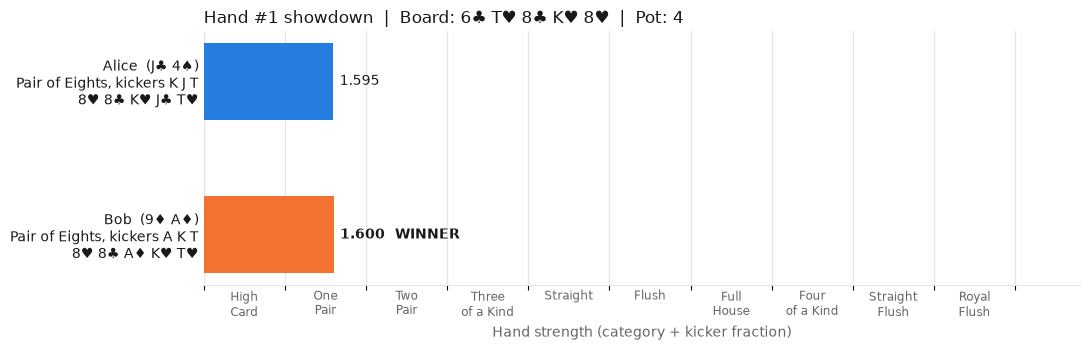

In [217]:
# 1.8 Horizontal showdown comparison bar chart
SEAT_COLORS = SERIES[:2]  # seat 1 blue, seat 2 orange


def plot_showdown(record, ax=None):
    """Bar length = hand strength (category + kicker fraction).

    Bars are colored by seat, so a player keeps the same color in every hand.
    """
    if record["hand_ranks"] is None:
        print(f"Hand #{record['hand']} ended by a fold: nothing to compare.")
        return None
    ranks = record["hand_ranks"]
    names = record["seats"]
    if ax is None:
        _, ax = plt.subplots(figsize=(11, 3.6))

    for y, name in enumerate(names):
        rank = ranks[name]
        ax.barh(y, rank.strength, height=0.5, color=SEAT_COLORS[y], zorder=3)
        tag = ""
        if name in record["winners"]:
            tag = "  SPLIT" if len(record["winners"]) > 1 else "  WINNER"
        ax.text(
            rank.strength + 0.08,
            y,
            f"{rank.strength:.3f}{tag}",
            va="center",
            ha="left",
            fontsize=10,
            color=INK,
            fontweight="bold" if tag else "normal",
        )

    ax.set_yticks(range(len(names)))
    ax.set_yticklabels(
        [
            f"{name}  ({format_cards(record['hole_cards'][name])})\n"
            f"{ranks[name].describe()}\n{format_cards(ranks[name].cards)}"
            for name in names
        ],
        fontsize=10,
        color=INK,
    )
    ax.invert_yaxis()

    ax.set_xlim(0, 10.8)
    # Gridlines mark category boundaries; labels sit in the middle of each band.
    ax.set_xticks(range(11))
    ax.set_xticklabels([])
    ax.set_xticks([c + 0.5 for c in HandCategory], minor=True)
    ax.set_xticklabels(
        [c.label.replace(" ", "\n", 1) for c in HandCategory],
        minor=True,
        fontsize=8.5,
        color=MUTED,
    )
    ax.tick_params(axis="x", which="minor", length=0)
    ax.grid(axis="x", which="major", color=GRID, linewidth=1, zorder=0)
    ax.set_xlabel("Hand strength (category + kicker fraction)", color=MUTED)
    for side in ("top", "right", "left"):
        ax.spines[side].set_visible(False)
    ax.spines["bottom"].set_color(GRID)
    ax.tick_params(axis="y", length=0)
    ax.set_title(
        f"Hand #{record['hand']} showdown  |  Board: "
        f"{format_cards(record['board'])}  |  Pot: {record['pot']}",
        loc="left",
        fontsize=12,
        color=INK,
    )
    plt.tight_layout()
    return ax


plot_showdown(demo_record)
plt.show()

## 1.9 Autonomous AI-vs-AI session (0 human players)
Two random bots play 500 hands with no human involved. This is the benchmarking loop Section 3 relies on. The key sanity check is **chip conservation**: the engine asserts after every hand that no chips were created or destroyed.

Hands played: 500 | showdowns: 279 | folds: 221
RandomBot-1: +947 chips (+94.7 big blinds per 100 hands)
RandomBot-2: -947 chips (-94.7 big blinds per 100 hands)
Chips conserved: True
Showdown hand categories: {'One Pair': 248, 'Two Pair': 125, 'High Card': 103, 'Three of a Kind': 33, 'Straight': 20, 'Full House': 16, 'Flush': 13}


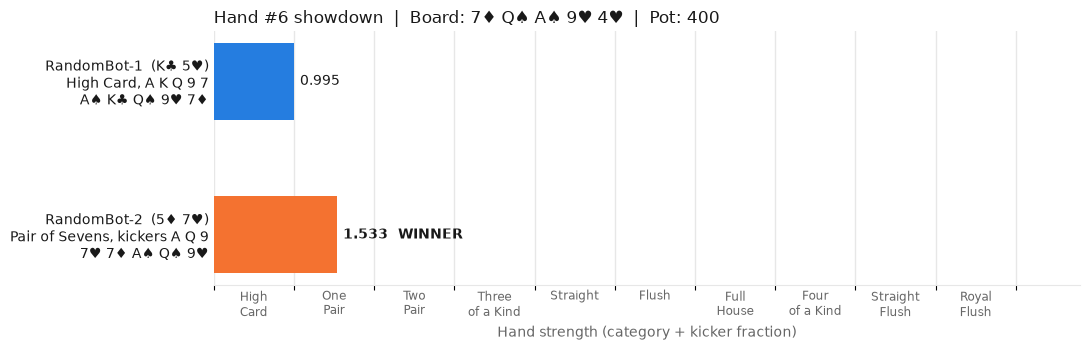

In [218]:
# 1.9 Autonomous AI-vs-AI session (0 human players)
session = GameEngine(
    Player("RandomBot-1", 200, RandomAgent(rng=random.Random(1))),
    Player("RandomBot-2", 200, RandomAgent(rng=random.Random(2))),
    seed=2026,
    verbose=False,
)
# No-limit random bots bust each other within a few hands, so stacks are
# reset to 200 before every hand and results are tracked per hand.
history = session.play_session(max_hands=500, reset_stacks=True)

showdowns = [h for h in history if h["result"] == "showdown"]
categories = Counter(
    rank.category.label for h in showdowns for rank in h["hand_ranks"].values()
)
winnings = Counter()
for h in history:
    winnings.update(h["net"])
print(
    f"Hands played: {len(history)} | showdowns: {len(showdowns)} | "
    f"folds: {len(history) - len(showdowns)}"
)
for name, net in winnings.items():
    bb_per_100 = net / session.big_blind / len(history) * 100
    print(f"{name}: {net:+d} chips ({bb_per_100:+.1f} big blinds per 100 hands)")
print("Chips conserved:", sum(winnings.values()) == 0)
print("Showdown hand categories:", dict(categories.most_common()))

# Chart the biggest showdown pot of the session.
if showdowns:
    plot_showdown(max(showdowns, key=lambda h: h["pot"]))
    plt.show()

## 1.10 The Expected Value (EV) formula
*Owner: Augustine*

Expected value is the average result of a decision if it were repeated many times. With equity $e$ (the share of the pot we win on average):

- **Call:** $\;EV_{call} = e\,(P + c) - c$, where $P$ is the pot (already including the opponent's bet) and $c$ is our cost to call.
- **Bet / raise:** if the opponent folds with probability $f$ we win the pot now; otherwise the pot grows and we win our equity share of it:
$$EV_{bet} = f\,P + (1 - f)\,\big[e\,(P + b + o) - b\big]$$
  where $b$ is what we put in and $o$ what the opponent must add to call.
- **Fold:** $EV = 0$ from this point on.

A call is profitable exactly when $e > \frac{c}{P + c}$, the **pot odds**. The tests check that this equivalence holds.

In [219]:
# 1.10 Expected Value decision module


def calculate_ev(equity, pot_after, cost):
    """EV of paying `cost` to win an `equity` share of `pot_after`."""
    return (equity * pot_after) - cost


def get_equity(result):
    """calculate_equity() result -> equity fraction (ties = half)."""
    return (result["win"] + result["tie"] / 2) / 100


def calculate_call_ev(equity, pot, cost):
    """EV of calling `cost` into `pot` (which includes the bet faced)."""
    return calculate_ev(equity, pot + cost, cost)


def calculate_bet_ev(equity, pot, bet_cost, opponent_cost, fold_probability):
    """EV of betting/raising.

    equity           : our equity as a fraction (0-1)
    pot              : the pot before our bet
    bet_cost         : chips we add with this bet/raise
    opponent_cost    : chips the opponent must add to call it
    fold_probability : chance the opponent folds (we then win the pot as it is)
    """
    if_fold = pot
    if_called = calculate_ev(equity, pot + bet_cost + opponent_cost, bet_cost)
    return fold_probability * if_fold + (1 - fold_probability) * if_called


call_ev = calculate_call_ev  # older name, kept for compatibility


def pot_odds(pot, cost):
    return cost / (pot + cost) if pot + cost > 0 else 0

In [220]:
# 1.11 EV formula unit tests

assert calculate_ev(0.50, 120, 20) == 40
assert calculate_ev(0.10, 120, 20) == -8
assert calculate_ev(0.25, 100, 25) == 0

assert get_equity({"win": 50, "tie": 20, "loss": 30}) == 0.60

assert calculate_call_ev(0.50, 100, 20) == 40

assert calculate_bet_ev(0.50, 100, 20, 20, 0) == 50

# Calling is +EV exactly when equity beats the pot odds.
pot, cost = 100, 20  # pot odds = 20 / 120 = 1/6
for e in (0.05, 0.10, 0.15, 0.20, 0.30, 0.60, 0.90):
    assert (calculate_call_ev(e, pot, cost) > 0) == (e > pot_odds(pot, cost))

# Betting: a sure fold wins the pot; a sure win collects everything.
assert calculate_bet_ev(0.0, 30, 4, 4, fold_probability=1.0) == 30
assert calculate_bet_ev(1.0, 30, 4, 4, fold_probability=0.0) == 30 + 4
# With no fold equity, betting beats checking only with equity > 50%.
for e in (0.3, 0.45, 0.55, 0.8):
    better = calculate_bet_ev(e, 30, 4, 4, 0.0) > calculate_call_ev(e, 30, 0)
    assert better == (e > 0.5), e
# Fold equity makes a pure bluff (0% equity) profitable.
assert calculate_bet_ev(0.0, 30, 4, 4, 0.0) < 0
assert calculate_bet_ev(0.0, 30, 4, 4, 0.5) > 0

print("All EV module tests passed!")

All EV module tests passed!


---
# 2. Intermediate Goal: The Probability Engine
*Owners: Kazzie (2.1–2.2), Marc (2.3–2.5)*

A rational player needs to know its **equity**: the probability of winning the pot if the hand went to showdown. Pre-flop there are about 2 billion combinations of opponent hand and board, far too many to enumerate on every decision. Instead we **sample** them (Monte Carlo). This section builds that estimator, proves it is correct, and then shows *how* correct it is: the error must shrink like $1/\sqrt{N}$, exactly as probability theory predicts.

## 2.1 Monte Carlo equity engine (Kazzie)

`calculate_equity(hole_cards, community_cards, num_simulations=10000)` estimates how often a hand **wins, ties or loses** heads-up by playing out thousands of random boards and scoring each showdown with the Milestone 1 `HandEvaluator`.

**How it works**
1. **Validate** the input: 2 hole cards, 0/3/4/5 board cards, no duplicate cards.
2. **Build the unseen deck once** (52 cards minus every known card). The loop never copies or shuffles the whole deck.
3. **Each simulation** draws, in one draw without replacement, the cards needed to complete the board to 5 (plus 2 opponent cards if the opponent is random), so cards can never collide.
4. **Showdown:** both 7-card hands are scored with `HandEvaluator.best_hand`; the higher `HandRank.key` wins, equal keys tie.
5. **Aggregate:** the win/tie/loss counts become percentages: `{"win": float, "tie": float, "loss": float}`.

**Why Monte Carlo?** Pre-flop there are about 2 billion possible opponent-hand + board combinations, too many to check one by one, so we sample 10,000. The result is an *estimate*, usually within about ±1 percentage point, so two runs can differ slightly. Pass `seed=` to get identical numbers every run.

**Optional extras** (the required signature still works unchanged):
- `opponent_cards=None`: `None` = opponent holds 2 random unseen cards (re-dealt each simulation); or pass their 2 known cards.
- `seed=None`: makes results reproducible (uses a private `random.Random(seed)`).

**Performance:** a score cache remembers the evaluator's result for any 7-card hand already seen. On the flop your hand can only come out about 1,000 ways, so most evaluations become instant lookups.

**Fast scorer:** inside the simulation loop, hands are scored with `fast_hand_key`, a single-pass 7-card evaluator (count ranks and suits once, then read off the category). It returns exactly the same `(category, tiebreak)` as `HandEvaluator.best_hand` (2.2 checks this on 50,000 random hands) but is about **25× faster**, because it doesn't build and score all 21 five-card combinations. This is what makes the 10,000-hand tournament in Section 3 practical.

In [221]:
# 2.1 Monte Carlo equity engine (Kazzie)
BOARD_SIZES = (0, 3, 4, 5)  # pre-flop, flop, turn, river


def to_cards(cards, label="cards"):
    """Turn input into a list of Card objects.

    Accepts None, a string like "Ah Kd", a list like ["Ah", "Kd"], or Card objects.
    """
    if cards is None:
        return []
    if isinstance(cards, str):
        cards = cards.split()

    result = []
    for card in cards:
        if isinstance(card, str):
            if len(card) != 2:
                raise ValueError(
                    f"Invalid card {card!r} in {label}: use e.g. 'Ah', 'Td', '7c'."
                )
            try:
                result.append(Card.from_str(card))
            except (KeyError, ValueError):
                raise ValueError(f"Invalid card {card!r} in {label}.") from None
        elif hasattr(card, "rank") and hasattr(card, "suit"):
            # Rebuild so it matches the current Card class (in case Cell 2 was re-run).
            result.append(Card(card.rank, card.suit))
        else:
            raise ValueError(f"Invalid card {card!r} in {label}.")
    return result


WHEEL_MASK = (1 << 14) | (1 << 5) | (1 << 4) | (1 << 3) | (1 << 2)


def straight_high(rank_bits):
    """Highest straight in a bitmask of ranks (bit r set = rank r present)."""
    for high in range(14, 5, -1):
        mask = 0b11111 << (high - 4)
        if rank_bits & mask == mask:
            return high
    if rank_bits & WHEEL_MASK == WHEEL_MASK:
        return 5
    return None


def fast_hand_key(cards):
    """HandRank.key of the best 5-card hand in 5-7 cards, in a single pass.

    Gives exactly the same (category, tiebreak) as
    HandEvaluator.best_hand(...).key (tested in 2.2) without building all
    21 five-card combinations, which makes Monte Carlo several times faster.
    """
    rank_counts = {}
    suit_ranks = {}
    for card in cards:
        rank_counts[card.rank] = rank_counts.get(card.rank, 0) + 1
        suit_ranks.setdefault(card.suit, []).append(card.rank)

    # Flushes and straight flushes.
    flush_ranks = None
    for ranks in suit_ranks.values():
        if len(ranks) >= 5:
            flush_ranks = sorted(ranks, reverse=True)
            high = straight_high(sum(1 << r for r in flush_ranks))
            if high == 14:
                return (HandCategory.ROYAL_FLUSH, (14,))
            if high:
                return (HandCategory.STRAIGHT_FLUSH, (high,))

    # Group ranks by how many times they appear, biggest rank first.
    by_count = {4: [], 3: [], 2: [], 1: []}
    for rank in sorted(rank_counts, reverse=True):
        by_count[rank_counts[rank]].append(rank)
    quads, trips, pairs, singles = (by_count[4], by_count[3], by_count[2], by_count[1])

    if quads:
        kicker = max(r for r in rank_counts if r != quads[0])
        return (HandCategory.FOUR_OF_A_KIND, (quads[0], kicker))
    if trips and (len(trips) > 1 or pairs):
        pair = max(trips[1:] + pairs)
        return (HandCategory.FULL_HOUSE, (trips[0], pair))
    if flush_ranks:
        return (HandCategory.FLUSH, tuple(flush_ranks[:5]))
    high = straight_high(sum(1 << r for r in rank_counts))
    if high:
        return (HandCategory.STRAIGHT, (high,))
    if trips:
        kickers = sorted(singles, reverse=True)[:2]
        return (HandCategory.THREE_OF_A_KIND, (trips[0], *kickers))
    if len(pairs) >= 2:
        kicker = max(r for r in rank_counts if r not in pairs[:2])
        return (HandCategory.TWO_PAIR, (pairs[0], pairs[1], kicker))
    if pairs:
        return (HandCategory.ONE_PAIR, (pairs[0], *singles[:3]))
    return (HandCategory.HIGH_CARD, tuple(singles[:5]))


def calculate_equity(
    hole_cards,
    community_cards,
    num_simulations=10000,
    opponent_cards=None,
    seed=None,
):
    """Estimate win / tie / loss percentages for `hole_cards` heads-up.

    hole_cards      : your 2 cards, e.g. "Ah Kh" or [Card, Card]
    community_cards : known board: 0 (pre-flop), 3 (flop), 4 (turn) or 5 (river) cards
    num_simulations : how many random boards to play out (default 10,000)
    opponent_cards  : None = opponent holds 2 random unseen cards; or their 2 known cards
    seed            : optional; the same seed gives the same result every run

    Returns {"win": float, "tie": float, "loss": float} as percentages (0-100) summing to 100.
    """
    # ---- 1. Validate the input ------------------------------------------
    hero = to_cards(hole_cards, "hole_cards")
    board = to_cards(community_cards, "community_cards")
    villain = to_cards(opponent_cards, "opponent_cards")

    if len(hero) != 2:
        raise ValueError(f"hole_cards must be exactly 2 cards, got {len(hero)}.")
    if len(board) not in BOARD_SIZES:
        raise ValueError(
            f"community_cards must be 0, 3, 4 or 5 cards, got {len(board)}."
        )
    if opponent_cards is not None and len(villain) != 2:
        raise ValueError(f"opponent_cards must be exactly 2 cards, got {len(villain)}.")
    if isinstance(num_simulations, bool) or not isinstance(num_simulations, int):
        raise ValueError("num_simulations must be a whole number.")
    if num_simulations < 1:
        raise ValueError("num_simulations must be at least 1.")

    known = hero + board + villain
    if len(set(known)) != len(known):
        raise ValueError("The same card appears more than once.")

    # ---- 2. Set up ONCE, before the loop (performance pass) -------------
    # Unseen deck = full 52 cards minus every known card. Built a single time;
    # inside the loop we only draw a few cards from it, never copy/shuffle it.
    known_set = set(known)
    unseen = [card for card in Deck().cards if card not in known_set]

    rng = random.Random(seed)  # private generator: doesn't affect other code
    cards_to_complete_board = 5 - len(board)
    random_opponent = opponent_cards is None
    cards_per_draw = cards_to_complete_board + (2 if random_opponent else 0)

    # Score cache: the best hand depends only on WHICH 7 cards a player has,
    # so a repeated 7-card hand is looked up instead of re-evaluated.
    score_cache = {}

    def score(hole, full_board):
        key = frozenset(hole + full_board)
        value = score_cache.get(key)
        if value is None:
            # (category, tiebreak): a bigger tuple is a better hand
            value = fast_hand_key(hole + full_board)
            score_cache[key] = value
        return value

    # ---- 3. The Monte Carlo loop -----------------------------------------
    wins = ties = losses = 0
    sample = rng.sample  # local name: slightly faster in a tight loop

    for _ in range(num_simulations):
        # One draw without replacement: opponent and board cards never collide.
        drawn = sample(unseen, cards_per_draw)

        if random_opponent:
            opponent = drawn[:2]
            full_board = board + drawn[2:]
        else:
            opponent = villain
            full_board = board + drawn

        # ---- 4. Showdown: score both 7-card hands with the evaluator ----
        hero_score = score(hero, full_board)
        opponent_score = score(opponent, full_board)

        if hero_score > opponent_score:
            wins += 1
        elif hero_score == opponent_score:
            ties += 1
        else:
            losses += 1

    # ---- 5. Counts -> percentages ----------------------------------------
    return {
        "win": 100.0 * wins / num_simulations,
        "tie": 100.0 * ties / num_simulations,
        "loss": 100.0 * losses / num_simulations,
    }


def show_equity(label, result):
    equity = result["win"] + result["tie"] / 2  # ties count as half a pot
    print(
        f"{label:<34} win {result['win']:5.1f}%  tie {result['tie']:4.1f}%  "
        f"loss {result['loss']:5.1f}%  | equity {equity:5.1f}%"
    )


show_equity(
    "AA vs KK, pre-flop", calculate_equity("As Ah", "", opponent_cards="Ks Kh", seed=1)
)
show_equity("AA vs random hand, pre-flop", calculate_equity("As Ah", "", seed=1))
show_equity(
    "AhKh vs QQ, flop Qh 7h 2c",
    calculate_equity("Ah Kh", "Qh 7h 2c", opponent_cards="Qs Qd", seed=1),
)
show_equity(
    "9s8s vs random, turn 7s 6d 2s Kc", calculate_equity("9s 8s", "7s 6d 2s Kc", seed=1)
)

AA vs KK, pre-flop                 win  82.2%  tie  0.7%  loss  17.1%  | equity  82.6%
AA vs random hand, pre-flop        win  85.3%  tie  0.5%  loss  14.2%  | equity  85.5%
AhKh vs QQ, flop Qh 7h 2c          win  25.7%  tie  0.0%  loss  74.3%  | equity  25.7%
9s8s vs random, turn 7s 6d 2s Kc   win  46.7%  tie  0.5%  loss  52.8%  | equity  47.0%


### 2.2 Equity engine tests (Kazzie)
Known pre-flop matchups, agreement with an **exact enumeration** of every runout, certain river outcomes, symmetry, input validation, and speed.

In [222]:
# 2.2 Equity engine tests (Kazzie)
def exact_vs_known(hero, board, villain):
    """Brute force: check EVERY possible runout (used to verify the Monte Carlo)."""
    hero, board, villain = parse_cards(hero), parse_cards(board), parse_cards(villain)
    known = set(hero + board + villain)
    unseen = [c for c in Deck().cards if c not in known]
    w = t = l = 0
    for runout in combinations(unseen, 5 - len(board)):
        full = board + list(runout)
        h, v = (
            HandEvaluator.best_hand(hero, full),
            HandEvaluator.best_hand(villain, full),
        )
        w, t, l = w + (h > v), t + (h == v), l + (h < v)
    n = w + t + l
    return {"win": 100 * w / n, "tie": 100 * t / n, "loss": 100 * l / n}


# The fast single-pass scorer agrees with the reference HandEvaluator.
agree_rng = random.Random(0)
all_cards = Deck().cards
categories_seen = set()
for _ in range(50_000):
    cards = agree_rng.sample(all_cards, agree_rng.choice((5, 6, 7)))
    fast = fast_hand_key(cards)
    assert fast == HandEvaluator.best_hand(cards[:2], cards[2:]).key, cards
    categories_seen.add(fast[0])
for hole, board, _ in [("Ah Kh", "Qh Jh Th 2c 3d", 0), ("Ac 2c", "3c 4c 5c Kd Kh", 0)]:
    cards = parse_cards(hole + " " + board)
    assert fast_hand_key(cards) == HandEvaluator.best_hand(cards[:2], cards[2:]).key
    categories_seen.add(fast_hand_key(cards)[0])
assert categories_seen == set(HandCategory), categories_seen
print("fast_hand_key matches HandEvaluator on 50,000 random hands (every category).")

# Output format: three float percentages that add up to 100.
r = calculate_equity("Ah Kh", "", num_simulations=2000, seed=1)
assert set(r) == {"win", "tie", "loss"} and all(
    isinstance(v, float) for v in r.values()
)
assert abs(sum(r.values()) - 100) < 1e-9

# Known pre-flop matchups.
r = calculate_equity("As Ah", "", opponent_cards="Ks Kh", seed=7)
assert 80 <= r["win"] <= 84, r  # AA vs KK ~82%
r = calculate_equity("As Ah", "", seed=7)
assert 83 <= r["win"] + r["tie"] / 2 <= 87.5, r  # AA vs random ~85%

# Monte Carlo agrees with an exact count of every runout (flop and turn).
for hero, board, villain in [
    ("Ah Kh", "Qh 7h 2c", "Qs Qd"),
    ("9s 8s", "7s 6d 2s Kc", "Ac Ad"),
]:
    exact = exact_vs_known(hero, board, villain)
    est = calculate_equity(hero, board, opponent_cards=villain, seed=3)
    assert all(abs(est[k] - exact[k]) < 2 for k in exact), (est, exact)

# River with both hands known: the answer is certain.
assert calculate_equity("Ah Kh", "Qh Jh Th 3s 4d", 500, "2c 2d") == {
    "win": 100.0,
    "tie": 0.0,
    "loss": 0.0,
}
assert calculate_equity("2c 2d", "Qh Jh Th 3s 4d", 500, "Ah Kh") == {
    "win": 0.0,
    "tie": 0.0,
    "loss": 100.0,
}
assert (
    calculate_equity("2c 3d", "As Ks Qs Js Ts", 500, "4h 5h")["tie"] == 100.0
)  # board plays
assert (
    calculate_equity("Ah Kh", "Qh Jh Th 3s 4d", 1000, seed=1)["win"] == 100.0
)  # royal vs anyone

# Swapping the players mirrors the result; seeds and input styles are consistent.
a = calculate_equity("As Ah", "", 3000, "Ks Kh", seed=9)
b = calculate_equity("Ks Kh", "", 3000, "As Ah", seed=9)
assert (a["win"], a["tie"], a["loss"]) == (b["loss"], b["tie"], b["win"])
assert (
    calculate_equity("Ah Kd", "7c 8c 9d", 3000, seed=5)
    == calculate_equity(["Ah", "Kd"], ["7c", "8c", "9d"], 3000, seed=5)
    == calculate_equity(parse_cards("Ah Kd"), parse_cards("7c 8c 9d"), 3000, seed=5)
)

# Invalid input is rejected with a clear ValueError.
bad_calls = [
    ("Ah", ""),
    ("Ah Kh Qh", ""),
    ("Ah Kh", "2c 3c"),
    ("Ah Kh", "2c 3c 4c 5c 6c 7c"),
    ("Ah Ah", ""),
    ("Ah Kh", "Ah 2c 3c"),
    ("Zz Kh", ""),
    ("Ax Kh", ""),
    ("10h Kh", ""),
]
bad_kwargs = [
    dict(opponent_cards="Kh Qs"),
    dict(opponent_cards="Qs"),
    dict(num_simulations=0),
    dict(num_simulations=2.5),
]
for args, kwargs in [(c, {}) for c in bad_calls] + [
    (("Ah Kh", ""), k) for k in bad_kwargs
]:
    try:
        calculate_equity(*args, **kwargs)
    except ValueError:
        continue
    raise AssertionError(f"Expected ValueError for {args} {kwargs}")

# Performance: 10,000 simulations on every street.
for label, board in [
    ("Pre-Flop", ""),
    ("Flop", "Qh 7c 2d"),
    ("Turn", "Qh 7c 2d 9s"),
    ("River", "Qh 7c 2d 9s 3h"),
]:
    start = time.perf_counter()
    calculate_equity("Ah Kh", board, num_simulations=10000, seed=1)
    print(f"10,000 simulations, {label:<8}: {time.perf_counter() - start:.2f} s")

print("\nAll equity engine tests passed.")

fast_hand_key matches HandEvaluator on 50,000 random hands (every category).
10,000 simulations, Pre-Flop: 0.13 s
10,000 simulations, Flop    : 0.09 s
10,000 simulations, Turn    : 0.06 s
10,000 simulations, River   : 0.03 s

All equity engine tests passed.


## 2.3 Error convergence (Marc)

**Theory.** Each simulated board is an independent trial whose outcome $X$ is 1 (win), ½ (tie) or 0 (loss). The estimate $\hat p_N$ is the average of $N$ trials, so by the Central Limit Theorem its standard error is

$$\text{SE}(\hat p_N) = \frac{\sigma}{\sqrt N}, \qquad \sigma^2 = \mathbb{E}[X^2] - p^2 .$$

On a log-log plot that is a straight line with **slope −½**: 100× more simulations buys only 10× more accuracy.

**Experiment.** For two spots where the *exact* equity $p$ is known (by enumerating every runout, as in 2.2), we run the simulator 30 times at each $N$ from 10 to 20,000 and measure the root-mean-square error $\sqrt{\overline{(\hat p_N - p)^2}}$.

**Tests.** The fitted slope must be close to −0.5, the measured error must match $\sigma/\sqrt N$ at every $N$, and at $N = 20{,}000$ the error must be well under one percentage point.

AhKh vs QsQd, flop Qh 7h 2c      exact equity  25.6% | fitted slope -0.507 | error/theory 0.89-1.12
9s8s vs AcAd, turn 7s 6d 2s Kc   exact equity  34.1% | fitted slope -0.491 | error/theory 0.81-1.07

Convergence tests passed: error shrinks like 1/sqrt(N).


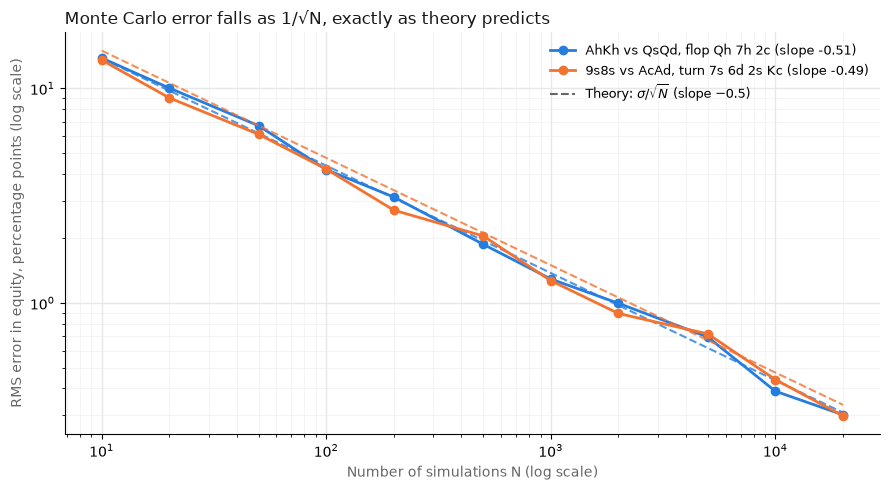

In [223]:
# 2.3 Monte Carlo error convergence (Marc)
SAMPLE_SIZES = [10, 20, 50, 100, 200, 500, 1_000, 2_000, 5_000, 10_000, 20_000]
REPEATS = 30
CONVERGENCE_SPOTS = [
    ("AhKh vs QsQd, flop Qh 7h 2c", "Ah Kh", "Qh 7h 2c", "Qs Qd"),
    ("9s8s vs AcAd, turn 7s 6d 2s Kc", "9s 8s", "7s 6d 2s Kc", "Ac Ad"),
]


def convergence_study(hero, board, villain, sizes=SAMPLE_SIZES, repeats=REPEATS):
    """Exact equity, per-trial sigma and RMS error at each sample size."""
    exact = exact_vs_known(hero, board, villain)
    p = get_equity(exact)
    second_moment = (exact["win"] + exact["tie"] / 4) / 100  # E[X^2]
    sigma = math.sqrt(second_moment - p**2)
    rms = []
    for n in sizes:
        errors = [
            get_equity(calculate_equity(hero, board, n, villain, seed=1000 * r + n)) - p
            for r in range(repeats)
        ]
        rms.append(math.sqrt(sum(e * e for e in errors) / repeats))
    return p, sigma, np.array(rms)


sizes = np.array(SAMPLE_SIZES)
convergence = {}
for label, hero_cards, board_cards, villain_cards in CONVERGENCE_SPOTS:
    p, sigma, rms = convergence_study(hero_cards, board_cards, villain_cards)
    slope = np.polyfit(np.log10(sizes), np.log10(rms), 1)[0]
    ratio = rms / (sigma / np.sqrt(sizes))
    convergence[label] = (p, sigma, rms, slope)
    print(
        f"{label:<32} exact equity {p:6.1%} | fitted slope {slope:+.3f}"
        f" | error/theory {ratio.min():.2f}-{ratio.max():.2f}"
    )

    # ---- tests ----
    assert -0.6 < slope < -0.4, f"Slope {slope:.3f} is not about -1/2."
    assert np.all((ratio > 0.6) & (ratio < 1.4)), ratio
    assert rms[-1] < 0.01, "Error at N=20,000 should be under 1 point."
print("\nConvergence tests passed: error shrinks like 1/sqrt(N).")

# ---- chart ----
fig, ax = plt.subplots(figsize=(9, 5))
for color, (label, (p, sigma, rms, slope)) in zip(SERIES, convergence.items()):
    ax.plot(
        sizes, 100 * sigma / np.sqrt(sizes), color=color, lw=1.5, ls="--", alpha=0.8
    )
    ax.plot(
        sizes,
        100 * rms,
        color=color,
        lw=2,
        marker="o",
        ms=6,
        label=f"{label} (slope {slope:.2f})",
    )
ax.plot(
    [],
    [],
    color=MUTED,
    ls="--",
    lw=1.5,
    label=r"Theory: $\sigma/\sqrt{N}$ (slope $-0.5$)",
)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("Number of simulations N (log scale)", color=MUTED)
ax.set_ylabel("RMS error in equity, percentage points (log scale)", color=MUTED)
ax.set_title(
    "Monte Carlo error falls as 1/√N, exactly as theory predicts",
    loc="left",
    fontsize=12,
    color=INK,
)
ax.grid(which="major", color=GRID, lw=1)
ax.grid(which="minor", color=GRID, lw=0.5, alpha=0.6)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

**Reading the chart.** Solid lines are the measured error; dashed lines are the theoretical $\sigma/\sqrt N$ for the same spot. They lie on top of each other across three orders of magnitude, so the simulator is unbiased and its uncertainty is fully explained by sampling noise. Practically, **10,000 simulations give roughly ±0.4 percentage points**, which is why that is the default, and why the agents in Section 3 can get away with only 50 simulations per decision (about ±6 points) when speed matters.

## 2.4 Pre-flop equity heatmap (Marc)

There are 1,326 two-card starting hands, but only **169 strategically different classes**: 13 pocket pairs, 78 suited and 78 offsuit combinations. The grid shows each class's equity against one random hand: pairs on the diagonal, **suited hands above** it, **offsuit hands below**.

This table is reused in Section 3: the EV agents look up their pre-flop equity here instead of re-simulating it on every decision, which makes the 10,000-hand tournament feasible.

**Tests:** 169 classes; well-known values (AA ≈ 85%, KK ≈ 82%, AKs ≈ 67%, AKo ≈ 65%, 22 ≈ 50%) within 3 points; AA is best; the worst hand is a low offsuit hand; bigger pairs beat smaller ones; and being suited adds a few points.

169 classes x 2,000 simulations in 5 s
Best: AA 83.8% | worst: 32o 32.6% | average suited bonus: +2.9%
Pre-flop table tests passed.


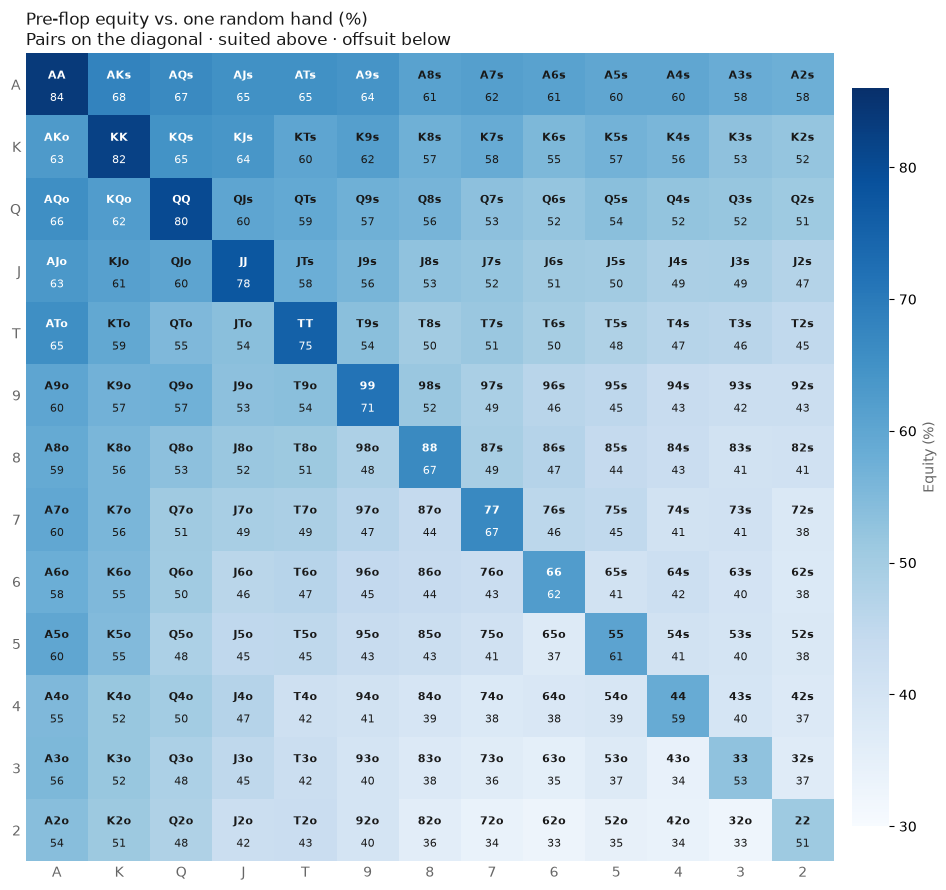

In [224]:
# 2.4 13x13 pre-flop equity heatmap (Marc)
PREFLOP_SIMS = 2_000  # per class: about 1 minute in total, +/- 1.1 points
GRID_RANKS = RANKS[::-1]  # "AKQJT98765432"


def class_name(row, col):
    """Grid cell -> hand class: above the diagonal suited, below offsuit."""
    high, low = GRID_RANKS[min(row, col)], GRID_RANKS[max(row, col)]
    if row == col:
        return high + low
    return high + low + ("s" if row < col else "o")


def example_hand(name):
    """One concrete hand for a class, e.g. 'AKs' -> Ah Kh, 'AKo' -> Ah Kd."""
    second_suit = "h" if name.endswith("s") else "d"
    return [Card.from_str(name[0] + "h"), Card.from_str(name[1] + second_suit)]


def preflop_equity_table(sims=PREFLOP_SIMS, seed=2026):
    """Equity (0-1) of all 169 starting-hand classes vs a random hand."""
    table = {}
    for row in range(13):
        for col in range(13):
            name = class_name(row, col)
            result = calculate_equity(
                example_hand(name), [], sims, seed=seed + 13 * row + col
            )
            table[name] = get_equity(result)
    return table


start = time.perf_counter()
PREFLOP_EQUITY = preflop_equity_table()
print(
    f"169 classes x {PREFLOP_SIMS:,} simulations in {time.perf_counter() - start:.0f} s"
)
equity_grid = np.array(
    [[PREFLOP_EQUITY[class_name(r, c)] for c in range(13)] for r in range(13)]
)

# ---- tests ----
assert len(PREFLOP_EQUITY) == 169
assert {"AKs", "AKo", "AA", "72o", "32s"} <= set(PREFLOP_EQUITY)
reference = {"AA": 0.852, "KK": 0.824, "AKs": 0.670, "AKo": 0.654, "22": 0.503}
for name, expected in reference.items():
    assert abs(PREFLOP_EQUITY[name] - expected) < 0.03, name
ranked = sorted(PREFLOP_EQUITY, key=PREFLOP_EQUITY.get)
assert ranked[-1] == "AA", ranked[-1]
worst = ranked[0]
assert worst.endswith("o") and RANK_VALUES[worst[0]] <= 7, worst
# Vectorized checks on the 13x13 grid.
pair_equity = np.diag(equity_grid)  # AA, KK, ..., 22 down the diagonal
assert np.all(pair_equity[:-3] > pair_equity[3:]), "Bigger pairs should win."
above = np.triu_indices(13, k=1)  # suited cells; the transpose holds offsuit twins
suited_bonus = (equity_grid[above] - equity_grid.T[above]).mean()
assert 0.015 < suited_bonus < 0.05, suited_bonus
print(
    f"Best: AA {PREFLOP_EQUITY['AA']:.1%} | worst: {worst} "
    f"{PREFLOP_EQUITY[worst]:.1%} | average suited bonus: "
    f"+{suited_bonus:.1%}"
)
print("Pre-flop table tests passed.")

# ---- chart ----
fig, ax = plt.subplots(figsize=(10, 9))
image = ax.imshow(100 * equity_grid, cmap="Blues", vmin=30, vmax=86)
for r in range(13):
    for c in range(13):
        value = 100 * equity_grid[r, c]
        ink = "white" if value > 62 else INK
        ax.text(
            c,
            r - 0.14,
            class_name(r, c),
            ha="center",
            va="center",
            fontsize=8,
            fontweight="bold",
            color=ink,
        )
        ax.text(
            c, r + 0.22, f"{value:.0f}", ha="center", va="center", fontsize=8, color=ink
        )
ax.set_xticks(range(13), list(GRID_RANKS))
ax.set_yticks(range(13), list(GRID_RANKS))
ax.tick_params(length=0, colors=MUTED)
for side in ax.spines.values():
    side.set_visible(False)
ax.set_title(
    "Pre-flop equity vs. one random hand (%)\n"
    "Pairs on the diagonal · suited above · offsuit below",
    loc="left",
    fontsize=12,
    color=INK,
)
colorbar = fig.colorbar(image, ax=ax, fraction=0.04, pad=0.02)
colorbar.set_label("Equity (%)", color=MUTED)
colorbar.outline.set_visible(False)
plt.tight_layout()
plt.show()

**Reading the heatmap.** Equity falls off from the top-left corner (big cards) toward the bottom-right (small cards). Three structural facts stand out:
- **Pairs** (diagonal) are strong even when small: 22 is a slight favourite over a random hand.
- **Suited** hands (upper triangle) are almost always a little better than their offsuit twins (lower triangle), but only by a few points. Suitedness matters less than beginners think.
- The spread is narrow: even the worst hand (32o, about 33%) is far from hopeless pre-flop, which is why folding too much is a real mistake heads-up.

## 2.5 Post-flop equity breakdown (Marc)

After the flop, hand strength separates sharply. The stacked bars show win / tie / loss probabilities against a random hand for seven typical holdings on the **same flop, K♥ 9♥ 4♣**: made hands, draws (which need help from the turn or river) and air.

**Tests:** each bar sums to 100%; the set is the best holding and the unpaired, undrawing hand is the worst; draws beat air.

Post-flop breakdown tests passed.
Set of nines             win  94.6%  tie  0.0%  loss   5.4%
Overpair (aces)          win  84.4%  tie  0.0%  loss  15.6%
Top pair, queen kicker   win  83.9%  tie  0.9%  loss  15.2%
Nut flush draw           win  71.0%  tie  0.9%  loss  28.2%
Bottom pair              win  52.6%  tie  3.7%  loss  43.7%
Gutshot straight draw    win  52.3%  tie  2.0%  loss  45.7%
Air (no pair, no draw)   win  15.9%  tie  4.5%  loss  79.6%


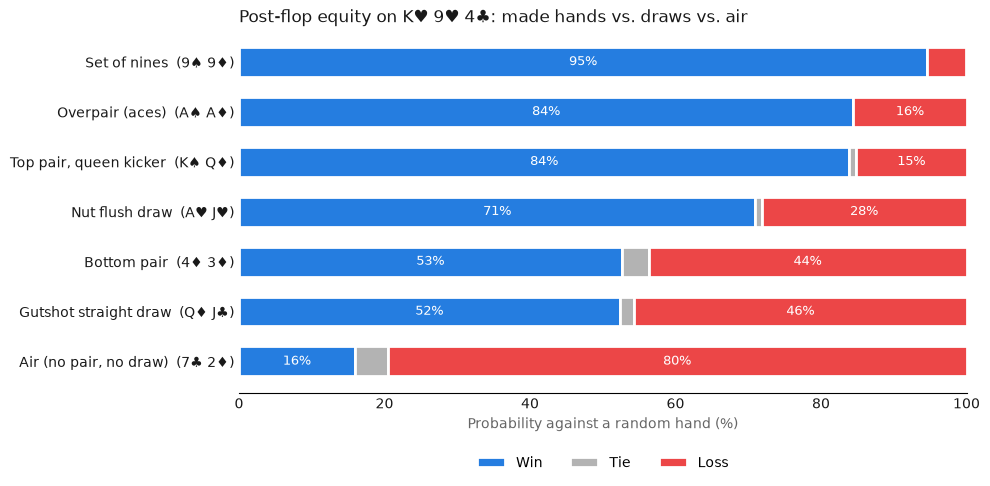

In [225]:
# 2.5 Post-flop stacked win/tie/loss bars (Marc)
FLOP = "Kh 9h 4c"
POSTFLOP_HANDS = [
    ("Set of nines", "9s 9d"),
    ("Overpair (aces)", "As Ad"),
    ("Top pair, queen kicker", "Ks Qd"),
    ("Nut flush draw", "Ah Jh"),
    ("Bottom pair", "4d 3d"),
    ("Gutshot straight draw", "Qd Jc"),
    ("Air (no pair, no draw)", "7c 2d"),
]

breakdown = {
    label: calculate_equity(hole, FLOP, 10_000, seed=11)
    for label, hole in POSTFLOP_HANDS
}
order = sorted(breakdown, key=lambda k: get_equity(breakdown[k]))

# ---- tests ----
for label, result in breakdown.items():
    assert abs(sum(result.values()) - 100) < 1e-9, label
assert order[-1] == "Set of nines" and order[0] == "Air (no pair, no draw)"
for draw in ("Nut flush draw", "Gutshot straight draw"):
    assert get_equity(breakdown[draw]) > get_equity(
        breakdown["Air (no pair, no draw)"]
    ), draw
print("Post-flop breakdown tests passed.")
for label in reversed(order):
    r = breakdown[label]
    print(
        f"{label:<24} win {r['win']:5.1f}%  tie {r['tie']:4.1f}%  "
        f"loss {r['loss']:5.1f}%"
    )

# ---- chart ----
fig, ax = plt.subplots(figsize=(10, 5))
y = np.arange(len(order))
left = np.zeros(len(order))
for key, name, color in (
    ("win", "Win", WIN_COLOR),
    ("tie", "Tie", TIE_COLOR),
    ("loss", "Loss", LOSS_COLOR),
):
    values = np.array([breakdown[label][key] for label in order])
    ax.barh(
        y,
        values,
        left=left,
        color=color,
        height=0.6,
        edgecolor="white",
        linewidth=2,
        label=name,
    )
    for yi, (start, width) in enumerate(zip(left, values)):
        if width >= 8:
            ax.text(
                start + width / 2,
                yi,
                f"{width:.0f}%",
                ha="center",
                va="center",
                fontsize=9,
                color="white",
            )
    left += values
hole_of = dict(POSTFLOP_HANDS)
ax.set_yticks(
    y, [f"{label}  ({format_cards(parse_cards(hole_of[label]))})" for label in order]
)
ax.set_xlim(0, 100)
ax.set_xlabel("Probability against a random hand (%)", color=MUTED)
ax.set_title(
    f"Post-flop equity on {format_cards(parse_cards(FLOP))}: "
    "made hands vs. draws vs. air",
    loc="left",
    fontsize=12,
    color=INK,
)
ax.tick_params(length=0, colors=INK)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
ax.legend(ncol=3, frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.14))
plt.tight_layout()
plt.show()

**Reading the chart.** Made hands (set, overpair, top pair) win most of the time, and pure air almost never does. The surprise is the **nut flush draw: 71%, above bottom pair (53%)**. It has no pair yet, but against a random hand its 9 flush outs plus an ace-high card are worth more than a weak made hand. Equity is about the cards still to come, not just what you hold now. This is exactly the information a rational agent uses, and what a heuristic like "bet only with top pair" (the Rock, Section 3) throws away: the Rock would fold this 71% hand to a bet.

---
# 3. Advanced Goal: Strategic Agents and the Tournament
*Owners: Jada (3.2–3.3), Poleen (3.4–3.11)*

We now put decision-makers on top of the engine (Section 1) and the probability engine (Section 2) and ask which kinds of reasoning win. Every agent sees the same `TableState` and plays **Fixed-Limit**, so differences in results come from strategy alone.

## 3.1 The agents on the two game-theoretic axes

| Agent | Rationality | Equilibrium | How it decides |
|---|---|---|---|
| **Random** | None (baseline) | Static | Picks a legal action at random |
| **Maniac** (loose/aggressive) | Bounded: ignores its cards | Static | Bets/raises 85% of the time, never folds |
| **Calling Station** (loose/passive) | Bounded: one equity check | Static | Checks/calls; folds only to a huge bet with exactly 0% equity |
| **Rock** (tight/passive) | Bounded: rule of thumb | Static | Plays the top ~15% of hands; after the flop bets/calls only with top pair or better |
| **EV agent** | Rational | Static | Maximises EV using its equity, assuming the opponent never folds |
| **Adaptive** | Rational | **Dynamic** | Same EV maths, but learns how often *this* opponent folds and bluffs accordingly |

The positions on the map are **ordinal** (a ranking, not a measurement). Section 3.10 checks them against measured behaviour.

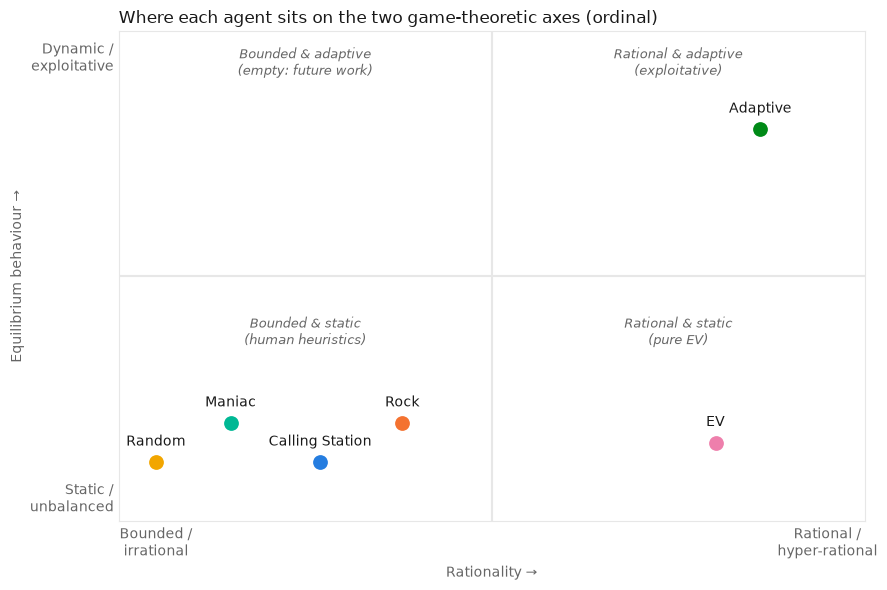

In [226]:
# 3.1 Conceptual map of the agents (rationality x equilibrium)
AGENT_ORDER = ["Calling Station", "Rock", "Maniac", "Random", "EV", "Adaptive"]
AGENT_COLORS = dict(zip(AGENT_ORDER, SERIES))
AXIS_POSITIONS = {  # (rationality, adaptivity), ordinal 0-1
    "Random": (0.05, 0.12),
    "Maniac": (0.15, 0.20),
    "Calling Station": (0.27, 0.12),
    "Rock": (0.38, 0.20),
    "EV": (0.80, 0.16),
    "Adaptive": (0.86, 0.80),
}

fig, ax = plt.subplots(figsize=(9, 6))
ax.axvline(0.5, color=GRID, lw=1.5)
ax.axhline(0.5, color=GRID, lw=1.5)
QUADRANT_LABELS = [
    (0.25, 0.97, "Bounded & adaptive\n(empty: future work)"),
    (0.75, 0.97, "Rational & adaptive\n(exploitative)"),
    (0.25, 0.42, "Bounded & static\n(human heuristics)"),
    (0.75, 0.42, "Rational & static\n(pure EV)"),
]
for x, y_pos, text in QUADRANT_LABELS:
    ax.text(
        x, y_pos, text, ha="center", va="top", fontsize=9, color=MUTED, style="italic"
    )
for name, (x, y_pos) in AXIS_POSITIONS.items():
    ax.scatter(
        x,
        y_pos,
        s=160,
        color=AGENT_COLORS[name],
        zorder=3,
        edgecolor="white",
        linewidth=2,
    )
    ax.annotate(
        name,
        (x, y_pos),
        xytext=(0, 12),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        color=INK,
    )
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
ax.set_xticks([0.05, 0.95], ["Bounded /\nirrational", "Rational /\nhyper-rational"])
ax.set_yticks([0.05, 0.95], ["Static /\nunbalanced", "Dynamic /\nexploitative"])
ax.tick_params(length=0, colors=MUTED)
ax.set_xlabel("Rationality →", color=MUTED)
ax.set_ylabel("Equilibrium behaviour →", color=MUTED)
for side in ax.spines.values():
    side.set_color(GRID)
ax.set_title(
    "Where each agent sits on the two game-theoretic axes (ordinal)",
    loc="left",
    fontsize=12,
    color=INK,
)
plt.tight_layout()
plt.show()

## 3.2 Heuristic behavioural bots (Jada)

| Bot | Style | Rule |
|---|---|---|
| `CallingStationBot` | Loose/Passive | Checks or calls; folds only to a massive bet with zero equity; never raises |
| `RockBot` | Tight/Passive | Plays about the top 15% of starting hands; after the flop, bets or calls only with top pair or better |
| `ManiacBot` | Loose/Aggressive | Ignores its cards; bets or raises about 85% of the time |

All three are **static**: they have no memory of previous hands and never react to the opponent.

In [227]:
# 3.2 BaseAgent + the three heuristic bots (Jada)
class BaseAgent(Agent, ABC):
    """Parent class for the heuristic bots.

    Each bot only writes get_action(game_state), which returns
    (action, amount) with action = "fold" | "call" | "bet" | "raise".
      * ("call", 0) means CHECK (there is nothing to pay).
      * For "bet"/"raise", amount is the "raise to" total (same as TableState).

    decide() translates that answer into the format GameEngine understands.
    """

    name = "Base"

    @abstractmethod
    def get_action(self, game_state):
        """Return ("fold" | "call" | "bet" | "raise", amount)."""
        raise NotImplementedError

    # ----- helpers shared by the bots --------------------------------------
    @staticmethod
    def fold():
        return ("fold", 0)

    @staticmethod
    def check_or_call(state):
        return ("call", min(state.to_call, state.chips))

    def check_or_fold(self, state):
        return self.check_or_call(state) if state.to_call == 0 else self.fold()

    def bet_or_raise(self, state, pot_fraction):
        """Bet/raise a fraction of the pot; check/call if that isn't allowed."""
        legal = state.legal_actions
        for kind in ("bet", "raise"):
            if kind in legal:
                if state.betting == "limit":  # fixed size
                    return (kind, state.min_raise_to)
                return (kind, state.raise_to_for_pot_fraction(pot_fraction))
        if "all-in" in legal:  # too few chips for a full-size raise
            kind = "bet" if state.current_bet == 0 else "raise"
            return (kind, state.max_raise_to)
        return self.check_or_call(state)

    # ----- adapter for GameEngine ------------------------------------------
    def decide(self, state):
        action, amount = self.get_action(state)
        legal = state.legal_actions
        if action == "call":
            return "check" if "check" in legal else "call"
        if action == "fold":
            return "fold" if "fold" in legal else "check"  # never fold for free
        if action in legal:
            return (action, amount)
        return "all-in"  # bet_or_raise only gets here when all-in is legal


class CallingStationBot(BaseAgent):
    """Loose/Passive: checks or calls everything and never bets or raises.

    It folds ONLY if BOTH are true:
      1. the bet is massive (at least the size of the pot before it, or at
         least half of the bot's remaining chips), and
      2. its estimated equity (win% + tie%) is zero.
    """

    name = "CallingStation"

    def __init__(self, num_simulations=500, seed=None, equity_fn=None):
        self.num_simulations = num_simulations
        self.rng = random.Random(seed)
        self.equity_fn = equity_fn or calculate_equity  # tests can swap this

    @staticmethod
    def is_massive_bet(state):
        if state.to_call <= 0:
            return False
        pot_before_bet = state.pot - state.to_call
        return state.to_call >= pot_before_bet or state.to_call >= state.chips / 2

    def has_zero_equity(self, state):
        result = self.equity_fn(
            list(state.hole_cards),
            list(state.board),
            num_simulations=self.num_simulations,
            seed=self.rng.randrange(10**9),
        )
        return result["win"] + result["tie"] == 0

    def get_action(self, game_state):
        # Equity is only computed when the bet is massive (saves time).
        if self.is_massive_bet(game_state) and self.has_zero_equity(game_state):
            return self.fold()
        return self.check_or_call(game_state)


# ----- The Rock's starting-hand tier list (about the top 15%) --------------
# Notation: "AKs" = same suit, "AKo" = different suits, "77" = pocket pair.
ROCK_TIERS = {
    1: ("AA", "KK", "QQ", "JJ", "AKs"),
    2: ("TT", "99", "AKo", "AQs", "AJs", "KQs"),
    3: ("88", "77", "AQo", "ATs", "KJs", "KTs", "QJs", "JTs"),
    4: (
        "66",
        "AJo",
        "ATo",
        "KQo",
        "KJo",
        "QJo",
        "A9s",
        "A8s",
        "A7s",
        "K9s",
        "QTs",
        "T9s",
    ),
}
ROCK_PLAYABLE = frozenset(hand for tier in ROCK_TIERS.values() for hand in tier)


def hand_notation(hole_cards):
    """Two cards -> tier-list notation, e.g. Ah Kh -> 'AKs'."""
    high, low = sorted(hole_cards, key=lambda c: c.rank, reverse=True)
    text = high.rank_char + low.rank_char
    if high.rank == low.rank:
        return text
    return text + ("s" if high.suit == low.suit else "o")


def has_top_pair_or_better(hole_cards, board):
    """True if the HOLE CARDS give top pair or better.

    A pair or trips lying entirely on the board doesn't count, because the
    opponent has it too.
    """
    hole, board = list(hole_cards), list(board)
    if len(board) < 3:
        raise ValueError("Needs at least a flop (3 board cards).")

    best = HandEvaluator.best_hand(hole, board)
    board_counts = Counter(c.rank for c in board)

    # 1) Straight or better that the board doesn't already make by itself.
    if best.category >= HandCategory.STRAIGHT:
        if len(board) < 5:
            return True  # 3-4 board cards can't make these alone, except quads
        board_best = HandEvaluator.evaluate_five(board)
        if best.category > board_best.category:
            return True
        if best.category != HandCategory.FOUR_OF_A_KIND and best > board_best:
            return True

    # 2) Trips using at least one hole card.
    all_counts = Counter(c.rank for c in hole + board)
    if any(all_counts[c.rank] >= 3 and board_counts[c.rank] < 3 for c in hole):
        return True

    top = max(board_counts)
    first, second = hole[0].rank, hole[1].rank
    # 3) Overpair (pocket pair higher than every board card).
    if first == second:
        return first > top
    # 4) Two pair using BOTH hole cards.
    if first in board_counts and second in board_counts:
        return True
    # 5) Top pair.
    return top in (first, second)


class RockBot(BaseAgent):
    """Tight/Passive: plays only strong starting hands and never raises.

    Pre-flop : unplayable hand -> fold (checks if it is free).
               playable hand   -> call.
    Post-flop: top pair or better -> bet if nobody has bet, otherwise call.
               anything weaker    -> check if free, otherwise fold.
    """

    name = "Rock"
    BET_POT_FRACTION = 0.5

    def get_action(self, game_state):
        if game_state.street == "Pre-Flop":
            if hand_notation(game_state.hole_cards) in ROCK_PLAYABLE:
                return self.check_or_call(game_state)
            return self.check_or_fold(game_state)

        if not has_top_pair_or_better(game_state.hole_cards, game_state.board):
            return self.check_or_fold(game_state)
        if "bet" in game_state.legal_actions:
            return self.bet_or_raise(game_state, self.BET_POT_FRACTION)
        return self.check_or_call(game_state)


class ManiacBot(BaseAgent):
    """Loose/Aggressive: ignores its cards and bets/raises most of the time.

    With probability `aggression` it bets or raises a random big size;
    otherwise it checks/calls. It never folds.
    """

    name = "Maniac"
    POT_FRACTIONS = (0.75, 1.0, 1.5)

    def __init__(self, aggression=0.85, rng=None):
        if not 0 <= aggression <= 1:
            raise ValueError("aggression must be between 0 and 1.")
        self.aggression = aggression
        self.rng = rng or random.Random()

    def get_action(self, game_state):
        if self.rng.random() < self.aggression:
            return self.bet_or_raise(game_state, self.rng.choice(self.POT_FRACTIONS))
        return self.check_or_call(game_state)


print("Loaded: BaseAgent, CallingStationBot, RockBot, ManiacBot")

Loaded: BaseAgent, CallingStationBot, RockBot, ManiacBot


### 3.3 Heuristic bot tests (Jada)
Mock game states test each bot's rule directly (no hand needs to be played), then all three play 600 real hands in the engine, which raises an error on any illegal action.

In [228]:
# 3.3 Heuristic bot unit tests with mock game states (Jada)
def mock_state(
    hole, board="", to_call=0, pot=10, chips=200, legal=None, betting="no-limit"
):
    """Build a fake TableState so a bot can be tested without playing a hand."""
    board_cards = tuple(parse_cards(board))
    street = {0: "Pre-Flop", 3: "Flop", 4: "Turn", 5: "River"}[len(board_cards)]
    if legal is None:
        if to_call == 0:
            legal = ("check", "bet", "all-in")
        else:
            legal = ("fold", "call", "raise", "all-in")
    return TableState(
        street=street,
        betting=betting,
        board=board_cards,
        hole_cards=tuple(parse_cards(hole)),
        pot=pot,
        to_call=to_call,
        current_bet=to_call,
        street_bet=0,
        min_raise_to=max(2, 2 * to_call),
        max_raise_to=chips,
        bets_this_street=int(to_call > 0),
        chips=chips,
        opponent_chips=200,
        legal_actions=legal,
        action_history=(),
    )


def zero_equity(*args, **kwargs):  # fake equity results for testing
    return {"win": 0.0, "tie": 0.0, "loss": 100.0}


def some_equity(*args, **kwargs):
    return {"win": 5.0, "tie": 0.0, "loss": 95.0}


# ----- 1. BaseAgent --------------------------------------------------------
# "Abstract" means Python refuses to create it until get_action() is written.
assert "get_action" in BaseAgent.__abstractmethods__
print("PASS  BaseAgent requires get_action()")

# ----- 2. Calling Station --------------------------------------------------
station = CallingStationBot(equity_fn=some_equity, seed=1)
assert station.get_action(mock_state("7c 2d")) == ("call", 0)  # free check
assert station.decide(mock_state("7c 2d")) == "check"
assert station.get_action(mock_state("7c 2d", to_call=4)) == ("call", 4)
# Massive bet but SOME equity -> still calls.
assert station.get_action(mock_state("7c 2d", to_call=100, pot=110)) == ("call", 100)

hopeless = CallingStationBot(equity_fn=zero_equity, seed=1)
# Zero equity AND massive bet -> the only time it folds.
assert hopeless.get_action(mock_state("7c 2d", "As Ks Qh", to_call=100, pot=110)) == (
    "fold",
    0,
)
# Zero equity but SMALL bet -> still calls.
assert hopeless.get_action(mock_state("7c 2d", "As Ks Qh", to_call=2, pot=40)) == (
    "call",
    2,
)
# Never bets or raises, even with the best possible hand.
for to_call in (0, 2, 50, 200):
    nuts = mock_state("Ah Kh", "Qh Jh Th", to_call=to_call, pot=to_call + 10)
    assert CallingStationBot(seed=1).get_action(nuts)[0] == "call"
print("PASS  CallingStationBot")

# ----- 3. Rock -------------------------------------------------------------
rock = RockBot()

# The tier list really is about 15% of all 1,326 starting hands.
all_starts = list(combinations(Deck().cards, 2))
share = sum(hand_notation(h) in ROCK_PLAYABLE for h in all_starts) / len(all_starts)
assert 0.14 <= share <= 0.16, share

# Pre-flop
assert rock.get_action(mock_state("7c 2d", to_call=2)) == ("fold", 0)
assert rock.get_action(mock_state("7c 2d")) == ("call", 0)  # free: check, don't fold
for hand in ("Ah Ad", "Ah Kh", "6c 6d", "Qs Jd"):
    assert rock.get_action(mock_state(hand, to_call=2)) == ("call", 2), hand

# Post-flop: which holdings count as top pair or better?
strong = [
    ("Ah 5d", "As 9c 3h"),  # top pair
    ("Kh Kd", "Qs 9c 3h"),  # overpair
    ("9h 3d", "As 9c 3h"),  # two pair with both cards
    ("3c 3d", "As 9c 3h"),  # set
    ("Ah 9d", "9s 9c 3h"),  # trips using one hole card
    ("Jh Td", "Qs 9c 8h"),  # straight
    ("Th 2d", "5s 6c 7h 8d 9c"),  # higher straight than the board's
]
weak = [
    ("9h 5d", "As 9c 3h"),  # middle pair
    ("Qh Qd", "As 9c 3h"),  # pocket pair below the top card
    ("Ah Kd", "Qs 9c 3h"),  # nothing
    ("Ah 2d", "Ks Kc 5h"),  # the pair is only on the board
    ("Ah 2d", "7s 7c 7h"),  # the trips are only on the board
    ("2h 3d", "5s 6c 7h 8d 9c"),  # the board plays
    ("Ah 2d", "7s 7c 7h 7d 3c"),  # quads on board, only a kicker
]
for hole, board in strong:
    assert has_top_pair_or_better(parse_cards(hole), parse_cards(board)), (hole, board)
    assert rock.get_action(mock_state(hole, board, to_call=10, pot=30)) == ("call", 10)
    assert rock.get_action(mock_state(hole, board))[0] == "bet"
for hole, board in weak:
    assert not has_top_pair_or_better(parse_cards(hole), parse_cards(board)), (
        hole,
        board,
    )
    assert rock.get_action(mock_state(hole, board, to_call=10, pot=30)) == ("fold", 0)
    assert rock.get_action(mock_state(hole, board)) == ("call", 0)
print(f"PASS  RockBot (tier list = {share:.1%} of starting hands)")

# ----- 4. Maniac -----------------------------------------------------------
TRIALS = 2000
for to_call in (0, 10):
    maniac = ManiacBot(rng=random.Random(42))
    state = mock_state("7c 2d", "As Ks Qh", to_call=to_call, pot=30)  # junk hand
    results = [maniac.get_action(state) for _ in range(TRIALS)]
    aggressive = [r for r in results if r[0] in ("bet", "raise")]
    assert 0.80 <= len(aggressive) / TRIALS <= 0.90
    assert all(state.min_raise_to <= amt <= state.max_raise_to for _, amt in aggressive)
    assert {r[0] for r in results} == {"bet" if to_call == 0 else "raise", "call"}

always = ManiacBot(aggression=1.0, rng=random.Random(1))
# Raising not allowed -> calls instead.
assert always.get_action(mock_state("7c 2d", to_call=10, legal=("fold", "call"))) == (
    "call",
    10,
)
# Short stack: only all-in is possible -> engine receives "all-in".
short = mock_state("7c 2d", to_call=10, chips=15, legal=("fold", "call", "all-in"))
assert always.get_action(short) == ("raise", 15)
assert always.decide(short) == "all-in"
print("PASS  ManiacBot")

# ----- 5. Integration: the bots play real hands in the team's GameEngine ----
# GameEngine raises an error on any illegal action, so finishing proves legality.
matchups = [
    (CallingStationBot, RockBot),
    (CallingStationBot, ManiacBot),
    (RockBot, ManiacBot),
]
for betting in ("no-limit", "limit"):
    for first, second in matchups:
        bot_one, bot_two = first(), second()
        game = GameEngine(
            Player(bot_one.name, 200, bot_one),
            Player(bot_two.name, 200, bot_two),
            betting=betting,
            seed=3,
            verbose=False,
        )
        played = game.play_session(max_hands=100, reset_stacks=True)
        assert len(played) == 100
        for _, who, kind, _ in (a for hand in played for a in hand["actions"]):
            if who == "CallingStation":
                assert kind in ("check", "call", "fold"), kind
print("PASS  Integration: 600 real hands, no illegal actions")

print("\nAll heuristic bot tests passed.")

PASS  BaseAgent requires get_action()
PASS  CallingStationBot
PASS  RockBot (tier list = 14.9% of starting hands)
PASS  ManiacBot
PASS  Integration: 600 real hands, no illegal actions

All heuristic bot tests passed.


## 3.4 Rational agents: EV and Adaptive (Poleen)

**EV agent (rational, static).** On every decision it estimates its equity (pre-flop from the table in 2.4, after the flop with a 50-simulation Monte Carlo), computes the EV of each legal option with the formulas from 1.10, and picks the best. It assumes the opponent **never folds**, so it bets only for value (when its equity is above 50%) and calls only when its equity beats the pot odds.

**Adaptive agent (rational, dynamic).** Identical, except for the fold probability $f$ in $EV_{bet}$. After every hand it counts how often the opponent folded when facing one of *its* bets or raises, and estimates

$$\hat f = \frac{\text{folds} + 1}{\text{responses} + 4},$$

a smoothed rate that starts at a cautious 25% prior and converges to the opponent's true folding frequency. Against an opponent who folds a lot, a pure bluff becomes +EV and the agent starts bluffing; against one who never folds, it stops.

In [229]:
# 3.4 Probability-driven EV agent and Adaptive exploitative agent
class EVAgent(BaseAgent):
    """Rational & static: picks the legal action with the highest EV.

    Equity comes from a pre-flop lookup table (Section 2.4) when one is
    given, otherwise from a quick Monte Carlo estimate. The opponent is
    assumed never to fold (fold_probability = 0): it bets only for value.
    """

    name = "EV"

    def __init__(
        self, num_simulations=50, seed=None, equity_fn=None, preflop_table=None
    ):
        self.num_simulations = num_simulations
        self.rng = random.Random(seed)
        self.equity_fn = equity_fn or calculate_equity  # tests can swap it
        self.preflop_table = preflop_table
        self.equity_cache = {}  # (hole, board) -> equity, reused per street

    def estimate_equity(self, state):
        """Equity as a fraction (0-1) against a random hand."""
        if state.street == "Pre-Flop" and self.preflop_table:
            return self.preflop_table[hand_notation(state.hole_cards)]
        key = (state.hole_cards, state.board)
        if key not in self.equity_cache:
            self.equity_cache[key] = self._simulate_equity(state)
        return self.equity_cache[key]

    def _simulate_equity(self, state):
        result = self.equity_fn(
            list(state.hole_cards),
            list(state.board),
            num_simulations=self.num_simulations,
            seed=self.rng.randrange(10**9),
        )
        return get_equity(result)

    def fold_probability(self, state):
        """Chance the opponent folds to a bet. The pure EV agent assumes 0."""
        return 0.0

    def action_values(self, state):
        """List of (action, EV) pairs for every option considered."""
        equity = self.estimate_equity(state)
        cost = min(state.to_call, state.chips)
        options = [
            (self.check_or_call(state), calculate_call_ev(equity, state.pot, cost))
        ]
        if "fold" in state.legal_actions:
            options.append((self.fold(), 0.0))
        for kind in ("bet", "raise"):
            if kind in state.legal_actions:
                amount = state.min_raise_to
                bet_cost = amount - state.street_bet
                opponent_cost = max(0, amount - state.current_bet)
                ev = calculate_bet_ev(
                    equity,
                    state.pot,
                    bet_cost,
                    opponent_cost,
                    self.fold_probability(state),
                )
                options.append(((kind, amount), ev))
        return options

    def get_action(self, game_state):
        best_action, _ = max(
            self.action_values(game_state), key=lambda option: option[1]
        )
        return best_action


class AdaptiveAgent(EVAgent):
    """Rational & dynamic: an EV agent that learns its opponent's fold rate.

    After each hand it counts the opponent's responses to this agent's bets
    and raises, and uses the smoothed fold rate in the bet EV formula.
    """

    name = "Adaptive"
    PRIOR_FOLDS, PRIOR_RESPONSES = 1, 4  # prior guess: folds 25% of the time

    def __init__(self, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.opponent_folds = 0
        self.opponent_responses = 0

    def observe_hand(self, record, opponent_name):
        """Update the fold counts from a finished hand's action log."""
        previous = None  # (player, action) of the action before this one
        for _, player, action, _ in record["actions"]:
            faced_our_bet = (
                previous is not None
                and previous[0] != opponent_name
                and previous[1] in ("bet", "raise", "all-in")
            )
            if player == opponent_name and faced_our_bet:
                self.opponent_responses += 1
                self.opponent_folds += action == "fold"
            previous = (player, action)

    def fold_probability(self, state=None):
        return (self.opponent_folds + self.PRIOR_FOLDS) / (
            self.opponent_responses + self.PRIOR_RESPONSES
        )

### 3.5 Rational agent tests (Poleen)
A fake equity function pins the agent's equity to a chosen value, so each rule can be tested exactly:
1. The EV agent **calls exactly when equity beats the pot odds**.
2. With no fold equity it **value-bets exactly when equity is above 50%**.
3. It never folds when checking is free, and pre-flop it uses the lookup table instead of simulating.
4. The Adaptive agent **counts only the opponent's responses to its own bets**, starting from the 25% prior.
5. **Exploitation:** with 0% equity it bluffs against an opponent seen folding, and stops bluffing against one seen calling.
6. Both agents play real hands in both betting structures without an illegal action.

In [230]:
# 3.5 Rational agent unit tests (Poleen)
def fixed_equity(value):
    """Fake equity function: always returns `value` (0-1) as the win rate."""

    def equity_fn(*args, **kwargs):
        return {"win": 100.0 * value, "tie": 0.0, "loss": 100.0 * (1 - value)}

    return equity_fn


def must_not_simulate(*args, **kwargs):
    raise AssertionError("Pre-flop equity should come from the table.")


# ----- 1. Calls exactly when equity beats the pot odds ---------------------
facing_bet = mock_state("7c 2d", "As Ks Qh", to_call=10, pot=40, legal=("fold", "call"))
odds = pot_odds(facing_bet.pot, facing_bet.to_call)  # 10 / 50 = 20%
for e in (0.05, 0.10, 0.15, 0.25, 0.30, 0.60):
    action = EVAgent(equity_fn=fixed_equity(e)).get_action(facing_bet)
    expected = ("call", 10) if e > odds else ("fold", 0)
    assert action == expected, (e, action)
print(f"PASS  EV agent calls iff equity > pot odds ({odds:.0%})")

# ----- 2. Value-bets exactly when equity > 50% ----------------------------
checked_to = mock_state("7c 2d", "As Ks Qh", pot=10)
for e in (0.10, 0.30, 0.45, 0.55, 0.70, 0.95):
    kind = EVAgent(equity_fn=fixed_equity(e)).get_action(checked_to)[0]
    assert (kind == "bet") == (e > 0.5), (e, kind)
print("PASS  EV agent value-bets iff equity > 50%")

# ----- 3. Never folds for free; uses the pre-flop table -------------------
hopeless = EVAgent(equity_fn=fixed_equity(0.0))
assert hopeless.decide(mock_state("7c 2d", "As Ks Qh")) == "check"
table_user = EVAgent(equity_fn=must_not_simulate, preflop_table=PREFLOP_EQUITY)
assert (
    table_user.estimate_equity(mock_state("Ah Ad", to_call=1)) == (PREFLOP_EQUITY["AA"])
)
assert table_user.get_action(mock_state("Ah Ad", to_call=1))[0] == "raise"
assert table_user.get_action(mock_state("7c 2d", to_call=1)) == ("call", 1)
print("PASS  EV agent never folds for free and uses the pre-flop table")


# ----- 4. Adaptive bookkeeping -------------------------------------------
def fake_record(*actions):
    return {"actions": [("Flop",) + action for action in actions]}


learner = AdaptiveAgent()
assert learner.fold_probability() == 0.25, "Prior: 1 fold in 4."
learner.observe_hand(fake_record(("Adaptive", "bet", 2), ("Opp", "fold", 0)), "Opp")
assert (learner.opponent_folds, learner.opponent_responses) == (1, 1)
learner.observe_hand(fake_record(("Adaptive", "bet", 2), ("Opp", "call", 2)), "Opp")
assert (learner.opponent_folds, learner.opponent_responses) == (1, 2)
# The opponent betting and us calling is not a response to OUR bet.
learner.observe_hand(fake_record(("Opp", "bet", 2), ("Adaptive", "call", 2)), "Opp")
# A check-raise: the opponent folds to our raise -> counted.
learner.observe_hand(
    fake_record(("Opp", "bet", 2), ("Adaptive", "raise", 4), ("Opp", "fold", 2)), "Opp"
)
assert (learner.opponent_folds, learner.opponent_responses) == (2, 3)
assert learner.fold_probability() == 3 / 7
print("PASS  Adaptive agent counts only responses to its own bets")

# ----- 5. Exploitation: bluff a folder, never bluff a station ------------
bluff_spot = mock_state("7c 2d", "As Ks Qh", pot=10)  # 0% equity, no bet
vs_folder = AdaptiveAgent(equity_fn=fixed_equity(0.0))
vs_station = AdaptiveAgent(equity_fn=fixed_equity(0.0))
for _ in range(30):
    vs_folder.observe_hand(
        fake_record(("Adaptive", "bet", 2), ("Opp", "fold", 0)), "Opp"
    )
    vs_station.observe_hand(
        fake_record(("Adaptive", "bet", 2), ("Opp", "call", 2)), "Opp"
    )
assert vs_folder.fold_probability() > 0.9 > 0.05 > (vs_station.fold_probability())
assert vs_folder.get_action(bluff_spot)[0] == "bet", "Should bluff."
assert vs_station.get_action(bluff_spot) == ("call", 0), "Should check."
assert EVAgent(equity_fn=fixed_equity(0.0)).get_action(bluff_spot) == (
    "call",
    0,
), "The static EV agent never bluffs."
print("PASS  Adaptive agent bluffs folders and stops bluffing stations")

# ----- 6. Integration: legal play in real hands --------------------------
for betting in ("limit", "no-limit"):
    ev_bot = EVAgent(seed=1, preflop_table=PREFLOP_EQUITY)
    adaptive_bot = AdaptiveAgent(seed=2, preflop_table=PREFLOP_EQUITY)
    game = GameEngine(
        Player("EV", 200, ev_bot),
        Player("Adaptive", 200, adaptive_bot),
        betting=betting,
        seed=5,
        verbose=False,
    )
    for _ in range(100):
        for player in game.players:
            player.chips = 200
        adaptive_bot.observe_hand(game.play_hand(), "EV")
    assert game.total_chips() == 400
print("PASS  Integration: 200 real hands, no illegal actions")
print("\nAll rational agent tests passed.")

PASS  EV agent calls iff equity > pot odds (20%)
PASS  EV agent value-bets iff equity > 50%
PASS  EV agent never folds for free and uses the pre-flop table
PASS  Adaptive agent counts only responses to its own bets
PASS  Adaptive agent bluffs folders and stops bluffing stations
PASS  Integration: 200 real hands, no illegal actions

All rational agent tests passed.


## 3.6 Round-robin tournament runner (Poleen)
Every pair of agents plays **10,000 Fixed-Limit hands** (blinds 1/2, stacks reset to 200 before every hand so no match ends early). Results are reported in **bb/100**: big blinds won per 100 hands, the standard poker win-rate unit. Because poker results are very noisy, we also report each win rate's **standard error** (the per-hand standard deviation divided by $\sqrt{\text{hands}}$), so we can tell real edges from luck. The runner also records every agent's playing style (3.10) and the Adaptive agent's fold estimates (3.11).

> A full run takes about **2–3 minutes** (thanks to the fast scorer from 2.1). The results are also **saved to a file** next to the notebook (`tournament_10000_hands.pkl`), so later runs load them instantly. Delete that file to replay the tournament from scratch (for example after changing an agent), or lower `TOURNAMENT_HANDS` for a quick check.

In [231]:
# 3.6 Round-robin tournament runner (Poleen)
TOURNAMENT_HANDS = 10_000
STARTING_STACK, BIG_BLIND = 200, 2

BOT_FACTORIES = {
    "Calling Station": lambda: CallingStationBot(num_simulations=50, seed=1),
    "Rock": lambda: RockBot(),
    "Maniac": lambda: ManiacBot(rng=random.Random(2)),
    "Random": lambda: RandomAgent(rng=random.Random(3)),
    "EV": lambda: EVAgent(seed=4, preflop_table=PREFLOP_EQUITY),
    "Adaptive": lambda: AdaptiveAgent(seed=5, preflop_table=PREFLOP_EQUITY),
}
VOLUNTARY = ("call", "bet", "raise", "all-in")
AGGRESSIVE = ("bet", "raise", "all-in")


def style_from_actions(action_rows, names, hands):
    """Action counts and VPIP per player, computed with pandas (no loops).

    action_rows: one (hand, street, player, kind) tuple per action.
    VPIP counts the hands in which a player called or raised pre-flop.
    """
    acts = pd.DataFrame(action_rows, columns=["hand", "street", "player", "kind"])
    counts = pd.crosstab(acts["player"], acts["kind"]).reindex(names, fill_value=0)
    voluntary = acts["street"].eq("Pre-Flop") & acts["kind"].isin(VOLUNTARY)
    vpip = acts[voluntary].groupby("player")["hand"].nunique()
    counts["hands"] = hands
    counts["vpip"] = vpip.reindex(names, fill_value=0)
    return {name: Counter(counts.loc[name].astype(int).to_dict()) for name in names}


def run_match(name_a, name_b, hands, seed):
    """Play `hands` Fixed-Limit hands between two bots."""
    agents = {name_a: BOT_FACTORIES[name_a](), name_b: BOT_FACTORIES[name_b]()}
    players = [Player(name, STARTING_STACK, agent) for name, agent in agents.items()]
    engine = GameEngine(
        *players,
        small_blind=BIG_BLIND // 2,
        big_blind=BIG_BLIND,
        betting="limit",
        seed=seed,
        verbose=False,
    )
    nets = {name: [] for name in agents}
    action_rows = []  # (hand, street, player, kind) for the style statistics
    fold_estimates = {
        name: [] for name, agent in agents.items() if hasattr(agent, "observe_hand")
    }
    # Hands must be played in order (the Adaptive agent learns between them),
    # so this loop is sequential by nature.
    for hand in range(hands):
        for player in players:
            player.chips = STARTING_STACK
        record = engine.play_hand()
        assert sum(record["net"].values()) == 0, "Chips created or lost!"
        action_rows.extend(
            (hand, s, who, kind) for s, who, kind, _ in record["actions"]
        )
        for name, agent in agents.items():
            nets[name].append(record["net"][name])
            if name in fold_estimates:
                opponent = name_b if name == name_a else name_a
                agent.observe_hand(record, opponent)
                fold_estimates[name].append(agent.fold_probability())
    style = style_from_actions(action_rows, list(agents), hands)
    return nets, style, fold_estimates


def run_tournament(hands=TOURNAMENT_HANDS):
    """Round-robin of every pair in BOT_FACTORIES. Returns a results dict."""
    names = list(BOT_FACTORIES)
    bb100 = pd.DataFrame(np.nan, index=names, columns=names)
    std_err = bb100.copy()
    chips, folds = {}, {}
    style = {name: Counter() for name in names}
    total_start = time.perf_counter()
    for index, (a, b) in enumerate(combinations(names, 2)):
        start = time.perf_counter()
        nets, match_style, fold_estimates = run_match(a, b, hands, seed=2026 + index)
        for me, them in ((a, b), (b, a)):
            per_hand = np.array(nets[me]) / BIG_BLIND * 100  # in bb/100
            bb100.loc[me, them] = per_hand.mean()
            std_err.loc[me, them] = per_hand.std(ddof=1) / math.sqrt(hands)
            style[me].update(match_style[me])
        chips[(a, b)] = {n: np.cumsum([0] + nets[n]) for n in (a, b)}
        for name, estimates in fold_estimates.items():
            folds[(name, b if name == a else a)] = estimates
        print(
            f"{a:>15} vs {b:<15} {bb100.loc[a, b]:+8.1f} bb/100 "
            f"({time.perf_counter() - start:5.1f} s)"
        )
    print(f"Total: {time.perf_counter() - total_start:.0f} s")
    return {
        "hands": hands,
        "bb100": bb100,
        "se": std_err,
        "chips": chips,
        "style": style,
        "fold_estimates": folds,
    }

## 3.7 Run the tournament

In [232]:
# 3.7 Run the tournament, or load saved results (delete the file to re-run)
RESULTS_FILE = f"tournament_{TOURNAMENT_HANDS}_hands.pkl"
if os.path.exists(RESULTS_FILE):
    with open(RESULTS_FILE, "rb") as file:
        tournament = pickle.load(file)
    print(f"Loaded saved results from {RESULTS_FILE}.")
else:
    tournament = run_tournament()
    with open(RESULTS_FILE, "wb") as file:
        pickle.dump(tournament, file)
    print(f"Saved results to {RESULTS_FILE}.")
bb100, std_err = tournament["bb100"], tournament["se"]

# ---- sanity checks ----
# Zero-sum: the matrix plus its transpose is 0 everywhere (the diagonal is NaN).
matrix = bb100.to_numpy()
assert np.allclose(np.nan_to_num(matrix + matrix.T), 0, atol=1e-9), "Zero-sum."
assert all(
    len(curves[n]) == tournament["hands"] + 1
    for curves in tournament["chips"].values()
    for n in curves
)
print("\nTournament sanity checks passed (every match is zero-sum).")
display(bb100.round(1))

Loaded saved results from tournament_10000_hands.pkl.

Tournament sanity checks passed (every match is zero-sum).


,Calling Station,Rock,Maniac,Random,EV,Adaptive
Calling Station,NaN,-29.4,0.1,1.1,-112.6,-112.8
Rock,29.4,NaN,-52.9,-14.5,-27.2,-55.4
Maniac,-0.1,52.9,NaN,193.7,-333.4,-312.4
Random,-1.1,14.5,-193.7,NaN,-161.8,-242.0
EV,112.6,27.2,333.4,161.8,NaN,61.2
Adaptive,112.8,55.4,312.4,242.0,-61.2,NaN


## 3.8 Results matrix and overall ranking
Each cell is the **row agent's** win rate against the column agent, in bb/100. Blue means the row agent wins, red means it loses. Values in **bold** are statistically significant: more than 2 standard errors from zero, so very unlikely to be luck.

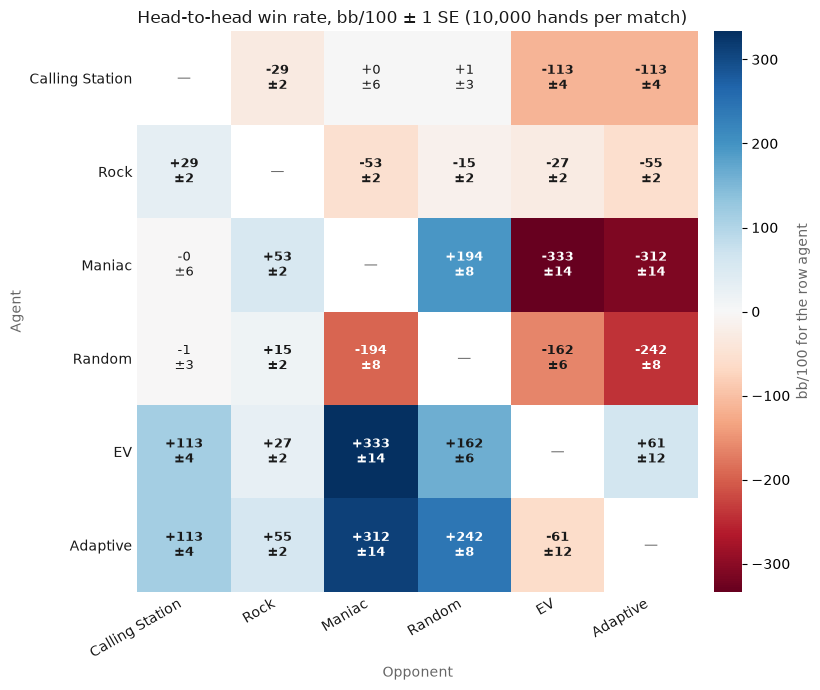

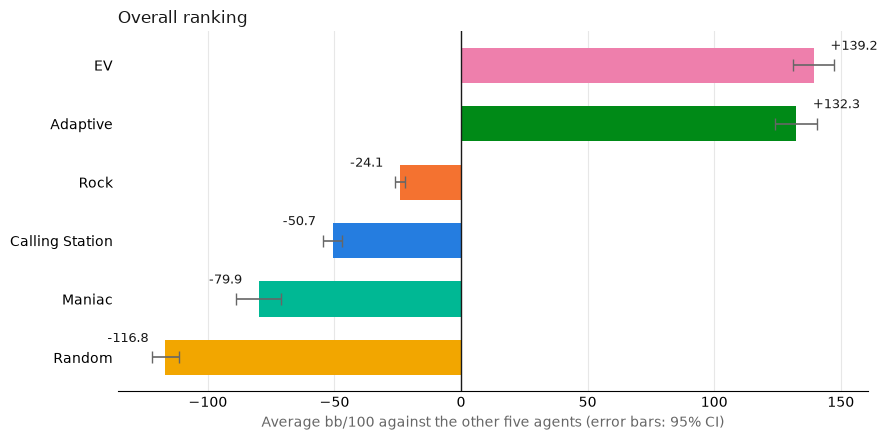

,avg bb/100,95% CI ±
EV,139.2,7.9
Adaptive,132.3,8.2
Rock,-24.1,1.9
Calling Station,-50.7,3.7
Maniac,-79.9,8.8
Random,-116.8,5.3


In [233]:
# 3.8 Head-to-head matrix and overall ranking
names = list(bb100.index)
limit = np.nanmax(np.abs(bb100.values))

fig, ax = plt.subplots(figsize=(9, 7))
image = ax.imshow(bb100.values, cmap="RdBu", vmin=-limit, vmax=limit)
for r, row_name in enumerate(names):
    for c, col_name in enumerate(names):
        if r == c:
            ax.text(c, r, "—", ha="center", va="center", color=MUTED)
            continue
        value, se = bb100.loc[row_name, col_name], std_err.loc[row_name, col_name]
        significant = abs(value) > 2 * se
        ink = "white" if abs(value) > 0.55 * limit else INK
        ax.text(
            c,
            r,
            f"{value:+.0f}\n±{se:.0f}",
            ha="center",
            va="center",
            fontsize=9,
            color=ink,
            fontweight="bold" if significant else "normal",
        )
ax.set_xticks(range(len(names)), names, rotation=30, ha="right")
ax.set_yticks(range(len(names)), names)
ax.tick_params(length=0, colors=INK)
for side in ax.spines.values():
    side.set_visible(False)
ax.set_xlabel("Opponent", color=MUTED)
ax.set_ylabel("Agent", color=MUTED)
ax.set_title(
    f"Head-to-head win rate, bb/100 ± 1 SE ({tournament['hands']:,} hands per match)",
    loc="left",
    fontsize=12,
    color=INK,
)
colorbar = fig.colorbar(image, ax=ax, fraction=0.04, pad=0.02)
colorbar.set_label("bb/100 for the row agent", color=MUTED)
colorbar.outline.set_visible(False)
plt.tight_layout()
plt.show()

# Overall ranking: average win rate over the 5 opponents, with a 95% CI.
k = len(names) - 1
overall = bb100.mean(axis=1)
overall_se = np.sqrt((std_err**2).sum(axis=1)) / k
ranking = overall.sort_values()
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.barh(
    range(len(ranking)),
    ranking.values,
    height=0.6,
    color=[AGENT_COLORS[n] for n in ranking.index],
    xerr=1.96 * overall_se[ranking.index].values,
    error_kw={"ecolor": MUTED, "capsize": 4, "lw": 1.2},
)
for y_pos, (name, value) in enumerate(ranking.items()):
    offset = 0.02 * limit * (1 if value >= 0 else -1)
    ax.text(
        value + offset,
        y_pos + 0.32,
        f"{value:+.1f}",
        va="center",
        ha="left" if value >= 0 else "right",
        fontsize=9,
        color=INK,
    )
ax.axvline(0, color=INK, lw=1)
ax.set_yticks(range(len(ranking)), ranking.index)
ax.set_xlabel(
    "Average bb/100 against the other five agents (error bars: 95% CI)", color=MUTED
)
ax.set_title("Overall ranking", loc="left", fontsize=12, color=INK)
ax.tick_params(length=0)
ax.grid(axis="x", color=GRID)
ax.set_axisbelow(True)
for side in ("top", "right", "left"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()
display(
    pd.DataFrame({"avg bb/100": overall, "95% CI ±": 1.96 * overall_se})
    .sort_values("avg bb/100", ascending=False)
    .round(1)
)

## 3.9 Cumulative chip graphs
One panel per match: each agent's running total of chips won over the 10,000 hands. A steady slope means a real, consistent edge; a jagged line that wanders around zero is luck.

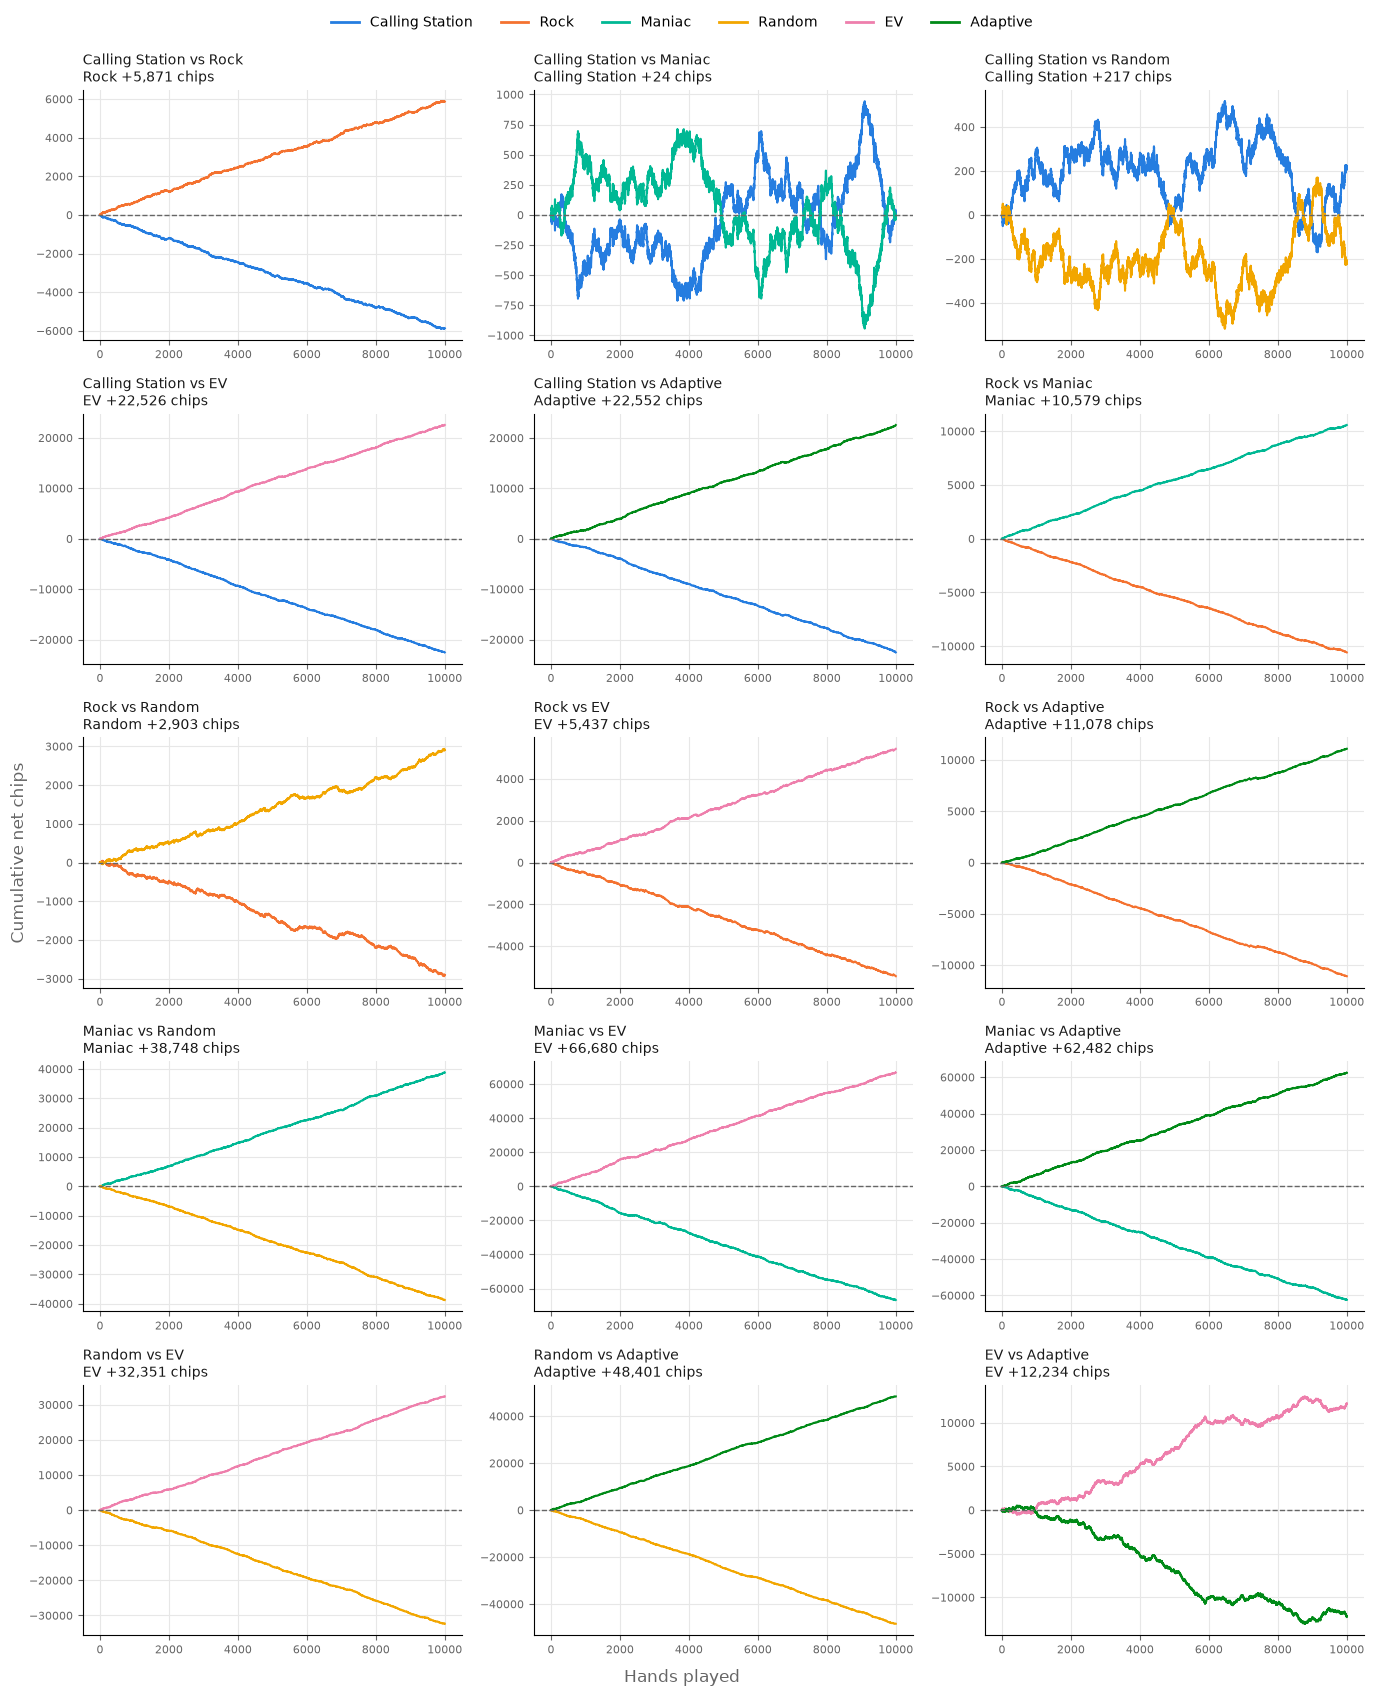

In [234]:
# 3.9 Cumulative chip graphs, one small panel per match
matchups = list(tournament["chips"].items())
fig, axes = plt.subplots(5, 3, figsize=(14, 17))
for ax, ((a, b), curves) in zip(axes.flat, matchups):
    for name in (a, b):
        ax.plot(curves[name], color=AGENT_COLORS[name], lw=1.5)
    winner = a if curves[a][-1] >= curves[b][-1] else b
    ax.axhline(0, color=MUTED, lw=1, ls="--")
    ax.set_title(
        f"{a} vs {b}\n{winner} {curves[winner][-1]:+,} chips",
        loc="left",
        fontsize=10,
        color=INK,
    )
    ax.grid(color=GRID)
    ax.tick_params(labelsize=8, colors=MUTED)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
handles = [plt.Line2D([], [], color=AGENT_COLORS[n], lw=2) for n in AGENT_ORDER]
fig.legend(
    handles,
    AGENT_ORDER,
    ncol=6,
    loc="upper center",
    frameon=False,
    bbox_to_anchor=(0.5, 1.0),
)
fig.supxlabel("Hands played", color=MUTED)
fig.supylabel("Cumulative net chips", color=MUTED)
plt.tight_layout(rect=(0, 0, 1, 0.98))
plt.show()

## 3.10 Do the archetypes play as labelled? (measured playing style)
Two standard poker statistics, measured over every hand of the tournament, test whether each bot really plays its archetype:
- **VPIP** (*voluntarily put money in pot*): the share of hands where the agent chose to call or raise pre-flop. High = **loose**, low = **tight**.
- **Aggression**: the share of the agent's actions that are bets or raises. High = **aggressive**, low = **passive**.

**Tests:** the Rock is the tightest heuristic bot; the Calling Station never bets or raises; the Maniac is the most aggressive and never folds.

Playing-style tests passed: each archetype plays as labelled.


,VPIP %,Aggression %,Fold %
Calling Station,71.4,0.0,0.0
Rock,11.5,9.8,39.5
Maniac,86.0,78.5,0.0
Random,68.3,29.8,8.1
EV,78.7,47.5,2.2
Adaptive,81.4,59.5,1.7


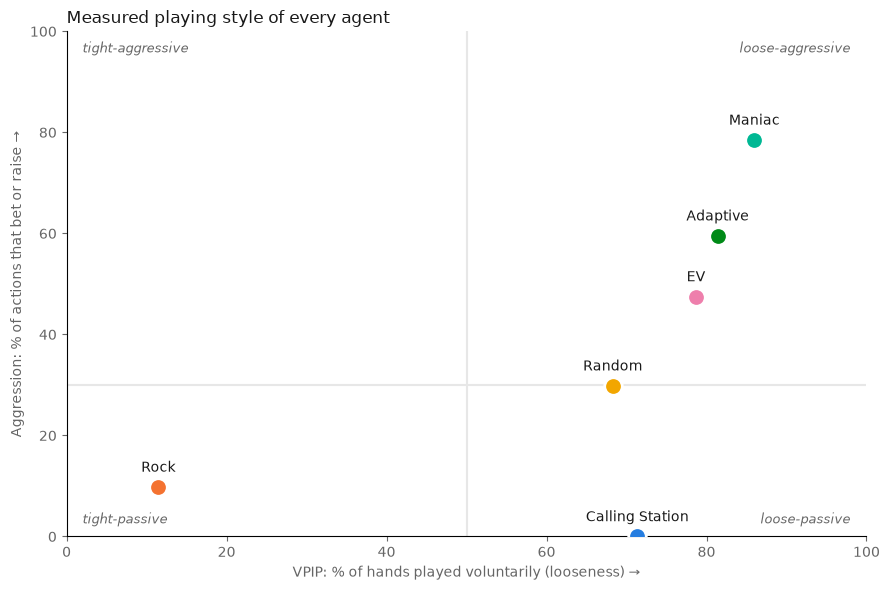

In [235]:
# 3.10 Measured playing style: VPIP vs aggression
KINDS = ["fold", "check", "call", "bet", "raise", "all-in"]
counts = (
    pd.DataFrame(tournament["style"])  # one column per agent
    .T.reindex(index=AGENT_ORDER, columns=KINDS + ["hands", "vpip"])
    .fillna(0)
)
actions = counts[KINDS].sum(axis=1)
style_table = pd.DataFrame(
    {
        "VPIP %": 100 * counts["vpip"] / counts["hands"],
        "Aggression %": 100 * counts[list(AGGRESSIVE)].sum(axis=1) / actions,
        "Fold %": 100 * counts["fold"] / actions,
    }
)

# ---- tests ----
heuristics = style_table.loc[["Calling Station", "Rock", "Maniac"]]
assert heuristics["VPIP %"].idxmin() == "Rock", "Rock should be tightest."
assert style_table.loc["Rock", "VPIP %"] < 25
assert style_table.loc["Calling Station", "Aggression %"] == 0
assert heuristics["Aggression %"].idxmax() == "Maniac"
assert style_table.loc["Maniac", "Fold %"] == 0, "The Maniac never folds."
print("Playing-style tests passed: each archetype plays as labelled.")
display(style_table.round(1))

# ---- chart ----
fig, ax = plt.subplots(figsize=(9, 6))
ax.axvline(50, color=GRID, lw=1.5)
ax.axhline(30, color=GRID, lw=1.5)
for text, (x, y_pos, ha, va) in {
    "tight-aggressive": (2, 98, "left", "top"),
    "loose-aggressive": (98, 98, "right", "top"),
    "tight-passive": (2, 2, "left", "bottom"),
    "loose-passive": (98, 2, "right", "bottom"),
}.items():
    ax.text(x, y_pos, text, ha=ha, va=va, fontsize=9, color=MUTED, style="italic")
for name, row in style_table.iterrows():
    ax.scatter(
        row["VPIP %"],
        row["Aggression %"],
        s=160,
        zorder=3,
        color=AGENT_COLORS[name],
        edgecolor="white",
        linewidth=2,
    )
    ax.annotate(
        name,
        (row["VPIP %"], row["Aggression %"]),
        xytext=(0, 11),
        textcoords="offset points",
        ha="center",
        fontsize=10,
        color=INK,
    )
ax.set_xlim(0, 100)
ax.set_ylim(0, 100)
ax.set_xlabel("VPIP: % of hands played voluntarily (looseness) →", color=MUTED)
ax.set_ylabel("Aggression: % of actions that bet or raise →", color=MUTED)
ax.set_title(
    "Measured playing style of every agent", loc="left", fontsize=12, color=INK
)
ax.tick_params(colors=MUTED)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

## 3.11 The Adaptive agent learning in real time
This is the **dynamic** axis made visible: the Adaptive agent's estimate of each opponent's fold-to-bet rate over the course of its matches. Every line starts at the 25% prior and moves toward that opponent's true tendency.

**Tests:** the estimates against the Maniac and the Calling Station (who essentially never fold) fall close to 0; the estimate against the Rock (who folds whenever it misses) stays clearly higher.

Adaptive learning tests passed.
  estimated fold rate vs Rock              64.4%
  estimated fold rate vs Random            14.5%
  estimated fold rate vs EV                 4.0%
  estimated fold rate vs Calling Station    0.0%
  estimated fold rate vs Maniac             0.0%


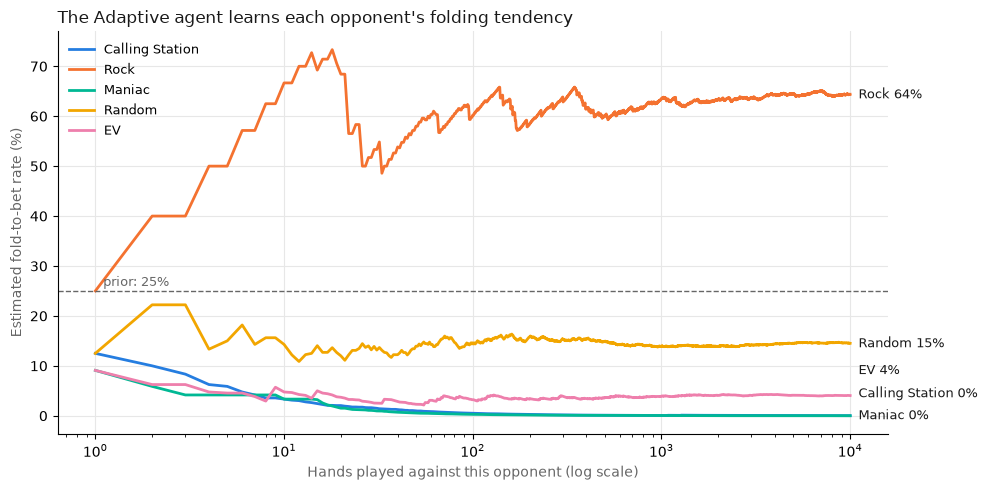

In [236]:
# 3.11 Adaptive agent's fold-rate estimate per opponent
estimates = {
    opp: values
    for (me, opp), values in tournament["fold_estimates"].items()
    if me == "Adaptive"
}
final = {opp: values[-1] for opp, values in estimates.items()}

# ---- tests ----
assert final["Maniac"] < 0.05 and final["Calling Station"] < 0.05, final
assert final["Rock"] > 0.2, final
assert final["Rock"] > max(final["Maniac"], final["Calling Station"])
print("Adaptive learning tests passed.")
for opp, value in sorted(final.items(), key=lambda item: -item[1]):
    print(f"  estimated fold rate vs {opp:<16} {value:6.1%}")

# ---- chart ----
fig, ax = plt.subplots(figsize=(10, 5))
for opp, values in estimates.items():
    ax.plot(
        np.arange(1, len(values) + 1),
        100 * np.array(values),
        color=AGENT_COLORS[opp],
        lw=2,
        label=opp,
    )
# End labels, nudged apart so equal values (e.g. two 0%) don't overlap.
label_y = {}
for opp in sorted(final, key=final.get):
    y_label = 100 * final[opp]
    if label_y:
        y_label = max(y_label, max(label_y.values()) + 4.5)
    label_y[opp] = y_label
for opp, y_label in label_y.items():
    ax.annotate(
        f"{opp} {100 * final[opp]:.0f}%",
        (len(estimates[opp]), y_label),
        xytext=(6, 0),
        textcoords="offset points",
        va="center",
        fontsize=9,
        color=INK,
    )
ax.axhline(25, color=MUTED, ls="--", lw=1)
ax.text(1.1, 26, "prior: 25%", color=MUTED, fontsize=9)
ax.set_xscale("log")
ax.set_xlabel("Hands played against this opponent (log scale)", color=MUTED)
ax.set_ylabel("Estimated fold-to-bet rate (%)", color=MUTED)
ax.set_title(
    "The Adaptive agent learns each opponent's folding tendency",
    loc="left",
    fontsize=12,
    color=INK,
)
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.grid(color=GRID)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
plt.tight_layout()
plt.show()

## 3.12 What the tournament shows

*Numbers below are from the saved 10,000-hands-per-match run (seeded, so a re-run reproduces them exactly). Standard errors are about 2–14 bb/100 depending on the match, so every difference called "significant" here is several standard errors from zero.*

**1. Rationality is what wins.** The two rational agents finish far ahead of everyone else: **EV +139 bb/100** and **Adaptive +132 bb/100** on average, and both beat every heuristic bot in every head-to-head match by a significant margin. All four bounded agents lose on average: Rock −24, Calling Station −51, Maniac −80, Random −117. Using probabilities and pot odds is worth far more than any style.

**2. Among the heuristics there is no single best style.** Rock beats Calling Station (+29), Maniac beats Rock (+53), yet Maniac only breaks even against Calling Station (+0.1 ± 6). The matchups are **non-transitive**, a little like rock-paper-scissors:
- The Maniac's constant betting makes the Rock fold its blinds away (Rock folds 40% of the time).
- The Calling Station never folds, so the Maniac's bluffs stop working and its edge disappears.
- The Maniac crushes Random (+194) because Random folds to pressure 8% of the time and plays aimlessly.

So how a heuristic does depends on who it's playing. That is the key weakness of **static** strategies.

**3. The archetypes play as labelled (3.10).** Measured over all hands: the Rock is the tightest (VPIP 11%), the Calling Station is the most passive (0% aggression, never folds), and the Maniac is the most aggressive (79% of its actions are bets or raises, never folds). The behavioural labels in the proposal are confirmed by data, not just by design.

**4. Adaptation helps against exploitable opponents, but not against a rational one.** The Adaptive agent learns each opponent's fold rate correctly (3.11): about 64% for the Rock, 15% for Random, 4% for EV and 0% for the Maniac and Calling Station. It turns that into extra profit where folding is common: **+55 vs Rock** (EV: +27) and **+242 vs Random** (EV: +162). But it **loses head-to-head to the static EV agent (−61 ± 12 bb/100)**.

The reason is a limit of what it learns. It tracks *how often* the opponent folds, but not *which hands* the opponent continues with. When the EV agent does call or raise, it does so exactly when its equity beats the pot odds, so it holds a strong hand. The Adaptive agent's extra bets (59% aggression vs EV's 48%) run into those strong hands. Against a disciplined opponent, a single frequency is not enough to exploit; you need a model of the opponent's **range**.

---
# 4. Discussion and Conclusion

## What we built and verified
- **Basic goal (Section 1).** We built a complete heads-up Hold'em engine in object-oriented Python. Its correctness is shown by unit tests:
  - every hand category, kickers, the wheel and split pots
  - the No-Limit and Fixed-Limit betting rules, including the 4-bet cap
  - chip conservation in every hand
  - the EV formulas, including the pot-odds equivalence
- **Intermediate goal (Section 2).** We built a Monte Carlo equity engine.
  - It matches an exact enumeration of every runout.
  - Its error follows the theoretical $\sigma/\sqrt N$ law (fitted log-log slopes of about −0.5).
  - A single-pass scorer, tested against the reference evaluator, makes it about 25× faster.
  - The 13×13 heatmap and the post-flop breakdown turn the engine's output into poker insight: suitedness is worth only a few points, and draws sit between made hands and air.
- **Advanced goal (Section 3).** We placed six agents on two game-theoretic axes, rationality and equilibrium behaviour.
  - Unit tests and measured statistics (VPIP, aggression, fold-rate learning) confirm each agent behaves as labelled.
  - A 150,000-hand round-robin tournament, with standard errors, measured how they perform.

## Answer to the research question
- **The rationality axis matters most.** Agents that reason with probabilities and expected value beat every heuristic by a wide margin.
- **The equilibrium axis has a subtler effect.** Adapting to the opponent pays off against opponents who give something away, such as the Rock's folding. But exploiting a frequency without modelling the opponent's hands costs money against a disciplined opponent: the Adaptive agent lost to the static EV agent.
- Static heuristics are **non-transitive**: none of them is best against all of the others.

## Limitations
- **Equity is computed against a random hand.** Real opponents bet strong hands and fold weak ones, so all our rational agents overestimate their equity when facing a bet. This is the main reason the Adaptive agent's bluffs fail against EV.
- **Bet sizing is minimal.** The rational agents only ever consider the minimum raise. That makes no difference in Fixed-Limit, but it is a real limitation in No-Limit.
- **The Adaptive agent learns a single statistic** (fold-to-bet) and assumes it is the same on every street and in every situation.
- **The heuristic bots are fully static.** No agent sits in the *bounded & adaptive* quadrant of the 3.1 map.
- **Results are specific to this pool of opponents.** bb/100 against these six bots does not measure how good an agent is in general.

## Future work
- **Range-based equity.** Update a probability distribution over the opponent's possible hands from their actions (Bayesian updating), and compute equity against that range instead of a random hand.
- **Fill the empty quadrant.** Build heuristic bots that switch style based on simple observations, for example a Rock that loosens up against a Maniac.
- **Equilibrium play.** Heads-up Limit Hold'em was essentially solved in 2015 using *Counterfactual Regret Minimization* (the Cepheus program). A small CFR agent on a simplified version of the game would add the missing "game-theory optimal" point to the map. That strategy can't be exploited, which would test whether the Adaptive agent's exploitation can beat it.

---
# Appendix A: Play It Yourself (1 human vs. AI)
Run the two cells below for a clickable table against a bot. The bot's cards stay face down unless the hand reaches showdown. It uses **No-Limit** betting (choose your size with the slider); pass `betting="limit"` to `GameEngine` to play the Fixed-Limit format of the study, and swap `RandomAgent()` for `EVAgent(preflop_table=PREFLOP_EQUITY)` or any other bot.

In [237]:
# Appendix A.1 Interactive table UI (1 human vs. AI)
FELT, FELT_EDGE, FELT_TEXT = "#1f5f3f", "#123d27", "#f4f1ea"
CARD_RED, CARD_BLACK = "#c8102e", "#16161a"


def action_phrase(kind, street_total):
    """'raises to 24', 'goes all-in (200)', ... for the status bar."""
    return {
        "fold": "folds",
        "check": "checks",
        "call": "calls",
        "bet": f"bets {street_total}",
        "raise": f"raises to {street_total}",
        "all-in": f"goes all-in ({street_total})",
    }[kind]


def card_html(card=None, face_down=False):
    """One playing card as inline HTML (an empty slot when card is None)."""
    box = (
        "display:inline-flex;flex-direction:column;align-items:center;"
        "justify-content:center;width:48px;height:68px;margin:0 3px;"
        "border-radius:7px;box-sizing:border-box;vertical-align:middle;"
        "font-family:system-ui,sans-serif;font-weight:700;line-height:1.05;"
    )
    if card is None:
        return f'<div style="{box}border:2px dashed rgba(255,255,255,.25);"></div>'
    if face_down:
        back = (
            "background:repeating-linear-gradient(45deg,#8c1d2c 0 5px,"
            "#a83242 5px 10px);border:3px solid #f4f1ea;"
        )
        return f'<div style="{box}{back}"></div>'
    color = CARD_RED if card.suit in "hd" else CARD_BLACK
    rank = "10" if card.rank == 10 else card.rank_char
    return (
        f'<div style="{box}background:#fdfcf8;border:1px solid #c9c6bc;'
        f'color:{color};font-size:19px;">{rank}'
        f'<span style="font-size:22px">{SUIT_SYMBOLS[card.suit]}</span></div>'
    )


class PokerTableUI:
    """A clickable heads-up table for one human seat against one bot.

    The UI drives GameEngine.hand_steps(): bot decisions are answered
    automatically, and the generator stays paused on the human's turn until
    a button is clicked. The bot's hole cards stay face down unless the hand
    reaches showdown.
    """

    def __init__(self, engine):
        self.engine = engine
        self.human = next(p for p in engine.players if p.agent.interactive)
        self.bot = next(p for p in engine.players if p is not self.human)
        self.starting_chips = {p.name: p.chips for p in engine.players}
        self.steps = None
        self.request = None  # (player, TableState) while the human must act
        self.record = None  # the finished hand's record

        def make_button(label, style):
            # Each button needs its own Layout: a shared one would hide or
            # show all buttons together.
            return widgets.Button(
                description=label,
                button_style=style,
                layout=widgets.Layout(width="150px", height="40px"),
            )

        self.fold_btn = make_button("Fold", "")
        self.passive_btn = make_button("Check", "info")
        self.aggressive_btn = make_button("Bet", "warning")
        self.all_in_btn = make_button("All-in", "danger")
        self.next_btn = make_button("Deal next hand", "success")
        self.fold_btn.on_click(lambda _: self._act("fold"))
        self.passive_btn.on_click(lambda _: self._act(self.passive_action))
        self.aggressive_btn.on_click(lambda _: self._act(self._sized_action()))
        self.all_in_btn.on_click(lambda _: self._act("all-in"))
        self.next_btn.on_click(lambda _: self._next_hand())
        self.passive_action = self.aggressive_action = None

        # No-limit sizing: a slider for the raise-to amount plus quick presets.
        self.size_slider = widgets.IntSlider(
            description="Raise to",
            continuous_update=True,
            layout=widgets.Layout(width="330px"),
        )
        self.size_slider.observe(lambda _: self._label_aggressive(), names="value")
        presets = []
        for label, fraction in (
            ("Min", None),
            ("½ Pot", 0.5),
            ("¾ Pot", 0.75),
            ("Pot", 1.0),
        ):
            preset = widgets.Button(
                description=label, layout=widgets.Layout(width="64px")
            )
            preset.on_click(lambda _, f=fraction: self._preset(f))
            presets.append(preset)
        self.sizing_row = widgets.HBox(
            [self.size_slider, *presets], layout=widgets.Layout(gap="6px")
        )

        self.table = widgets.HTML()
        self.log_box = widgets.HTML()
        self.chart_out = widgets.Output()
        controls = widgets.HBox(
            [
                self.fold_btn,
                self.passive_btn,
                self.aggressive_btn,
                self.all_in_btn,
                self.next_btn,
            ],
            layout=widgets.Layout(gap="8px", margin="8px 0 4px"),
        )
        self.root = widgets.VBox(
            [self.table, controls, self.sizing_row, self.log_box, self.chart_out]
        )

    # ----- game flow -------------------------------------------------------
    def show(self):
        display(self.root)
        self._next_hand()

    def _next_hand(self):
        with self.chart_out:
            self.chart_out.clear_output()
            if any(p.chips == 0 for p in self.engine.players):
                self._new_game()
            self.record = None
            self.steps = self.engine.hand_steps()
            self._advance(None)

    def _new_game(self):
        for player in self.engine.players:
            player.chips = self.starting_chips[player.name]
        self.engine.hand_number = 0
        self.engine.history = []

    def _act(self, action):
        if self.request is None or action is None:
            return
        with self.chart_out:
            self._advance(action)

    def _sized_action(self):
        if self.aggressive_action is None:
            return None
        return self.aggressive_action, self.size_slider.value

    def _preset(self, fraction):
        if self.request is None:
            return
        _, state = self.request
        self.size_slider.value = (
            state.min_raise_to
            if fraction is None
            else state.raise_to_for_pot_fraction(fraction)
        )

    def _advance(self, action):
        """Send an action, then let the bot play until it's our turn."""
        try:
            player, state = self.steps.send(action)
            while not player.agent.interactive:
                player, state = self.steps.send(player.agent.decide(state))
            self.request = (player, state)
        except StopIteration as finished:
            self.request = None
            self.record = finished.value
        self._render()
        if self.record and self.record["result"] == "showdown":
            plot_showdown(self.record)
            plt.show()

    # ----- rendering -------------------------------------------------------
    def _render(self):
        self.table.value = self._table_html()
        self.log_box.value = self._log_html()
        self._update_buttons()

    def _seat_html(self, player, reveal):
        if self.record:
            on_button = self.record["button"] == player.name
        else:
            on_button = self.engine.players[self.engine.button] is player
        dealer = (
            ' <span style="background:#f4f1ea;color:#16161a;border-radius:50%;'
            'padding:1px 6px;font-size:11px;font-weight:700">D</span>'
            if on_button
            else ""
        )
        cards = player.hole_cards or [None, None]
        hidden = not reveal and bool(player.hole_cards)
        cards_html = "".join(card_html(c, face_down=hidden) for c in cards)
        bet = (
            f'<span style="opacity:.8">bet {player.street_bet}</span>'
            if player.street_bet and not self.record
            else ""
        )
        folded = ' <span style="opacity:.7">(folded)</span>' if player.folded else ""
        return (
            f'<div style="display:flex;align-items:center;gap:14px;">'
            f'<div>{cards_html}</div><div style="line-height:1.5">'
            f"<b>{html.escape(player.name)}</b>{dealer}{folded}<br>"
            f"{player.chips} chips &nbsp;{bet}</div></div>"
        )

    def _table_html(self):
        showdown = bool(self.record) and self.record["result"] == "showdown"
        board = list(self.engine.board) + [None] * (5 - len(self.engine.board))
        pot = self.record["pot"] if self.record else self.engine.pot
        street = "Hand over" if self.record else self.engine.street
        # Chips already in the pot this hand still count as ours until it ends.
        net = (
            self.human.chips
            + self.human.total_bet
            - self.starting_chips[self.human.name]
        )
        return (
            f'<div style="background:{FELT};border:6px solid {FELT_EDGE};'
            f"border-radius:18px;padding:16px 20px;color:{FELT_TEXT};"
            f'font-family:system-ui,sans-serif;font-size:14px;max-width:640px;">'
            f'<div style="display:flex;justify-content:space-between;opacity:.85;'
            f'font-size:12px;"><span>Hand #{self.engine.hand_number} &middot; '
            f"{street}</span><span>Blinds {self.engine.small_blind}/"
            f"{self.engine.big_blind} &middot; Session {net:+d}</span></div>"
            f'<div style="margin:12px 0">{self._seat_html(self.bot, showdown)}</div>'
            f'<div style="text-align:center;margin:18px 0">'
            f"{''.join(card_html(c) for c in board)}"
            f'<div style="margin-top:8px;font-size:16px"><b>Pot: {pot}</b></div></div>'
            f'<div style="margin:12px 0">{self._seat_html(self.human, True)}</div>'
            f'<div style="margin-top:10px;padding:8px 12px;border-radius:8px;'
            f'background:rgba(0,0,0,.28);font-size:15px">{self._status()}</div>'
            f"</div>"
        )

    def _status(self):
        if self.request:
            _, state = self.request
            last = next(
                (a for a in reversed(self.engine.action_log) if a[1] == self.bot.name),
                None,
            )
            prefix = (
                f"{html.escape(self.bot.name)} {action_phrase(last[2], last[3])}. "
                if last and last[0] == state.street
                else ""
            )
            if state.to_call:
                return f"{prefix}<b>Your turn</b>: {min(state.to_call, state.chips)} to call."
            return f"{prefix}<b>Your turn</b>: check or bet."
        record = self.record
        if record["result"] == "fold":
            winner = record["winners"][0]
            loser = self.bot.name if winner == self.human.name else self.human.name
            return f"{html.escape(loser)} folded. <b>{html.escape(winner)} wins {record['pot']}.</b>"
        ranks = record["hand_ranks"]
        lines = [
            f"{html.escape(name)}: {rank.describe()}" for name, rank in ranks.items()
        ]
        if len(record["winners"]) > 1:
            outcome = f"<b>Split pot of {record['pot']}.</b>"
        else:
            outcome = (
                f"<b>{html.escape(record['winners'][0])} wins {record['pot']}.</b>"
            )
        if any(p.chips == 0 for p in self.engine.players):
            outcome += " Game over!"
        return "<br>".join(lines + [outcome])

    def _log_html(self):
        lines = [
            html.escape(msg.strip())
            for owner, msg in self.engine.hand_log
            if self.engine.can_see(owner) and msg.strip()
        ]
        return (
            '<div style="font-family:Consolas,monospace;font-size:12px;'
            "color:#3d3c38;background:#f4f2ec;border-radius:8px;"
            'padding:8px 12px;max-width:616px;line-height:1.45;">'
            + "<br>".join(lines[-14:])
            + "</div>"
        )

    @staticmethod
    def _show(widget, visible):
        widget.layout.display = None if visible else "none"

    def _update_buttons(self):
        in_hand = self.request is not None
        no_limit = self.engine.betting == "no-limit"
        for btn in (self.fold_btn, self.passive_btn, self.aggressive_btn):
            self._show(btn, in_hand)
        self._show(self.all_in_btn, in_hand and no_limit)
        self._show(self.next_btn, not in_hand)
        if not in_hand:
            self._show(self.sizing_row, False)
            game_over = any(p.chips == 0 for p in self.engine.players)
            self.next_btn.description = "New game" if game_over else "Deal next hand"
            return

        player, state = self.request
        legal = state.legal_actions
        self.fold_btn.disabled = "fold" not in legal
        if "check" in legal:
            self.passive_action, self.passive_btn.description = "check", "Check"
        else:
            amount = min(state.to_call, player.chips)
            self.passive_action, self.passive_btn.description = "call", f"Call {amount}"

        self.aggressive_action = next((a for a in ("bet", "raise") if a in legal), None)
        self.aggressive_btn.disabled = self.aggressive_action is None
        self.all_in_btn.disabled = "all-in" not in legal
        self.all_in_btn.description = f"All-in ({player.chips})"
        self._show(self.sizing_row, no_limit and self.aggressive_action is not None)
        if self.aggressive_action is not None:
            # Reset the range in an order the slider always accepts (min <= max).
            self.size_slider.min = 0
            self.size_slider.max = state.max_raise_to
            self.size_slider.min = state.min_raise_to
            self.size_slider.value = state.min_raise_to
        self._label_aggressive()

    def _label_aggressive(self):
        if self.request is None:
            return
        _, state = self.request
        if self.aggressive_action is None:
            self.aggressive_btn.description = "Raise"
            return
        amount = (
            self.size_slider.value
            if self.engine.betting == "no-limit"
            else state.min_raise_to
        )
        verb = "Bet" if self.aggressive_action == "bet" else "Raise to"
        suffix = " (all-in)" if amount == state.max_raise_to else ""
        self.aggressive_btn.description = f"{verb} {amount}{suffix}"

In [238]:
# Appendix A.2 Play! Re-run this cell to start a fresh match.
human_game = GameEngine(
    Player("Hero", 200, HumanAgent()),  # you
    Player("Bot", 200, RandomAgent()),
    verbose=False,
)
PokerTableUI(human_game).show()